# CVE5G Dataset v2.0 — Validation and Analysis

**Inputs per scenario** (`results/scenario_{n}/`): `cve5g_s{n}_bridge.pcap` (official capture),
`_n2.pcap`, `_filtered.pcap`, `_rfsim.pcap`, `_labels_time.csv`, `_labels_flow.csv`.
**Requirements:** `tshark` ≥ 4.0 (layer operator `#`), `capinfos`, `nfstream`, `scikit-learn`.

In [ ]:
import os
import re
import subprocess
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pandas.api.types import union_categoricals
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

BASE      = os.environ.get('CVE5G_BASE', os.path.expanduser('~/oai-workshops/cn/results/'))
SCENARIOS = ['scenario_1', 'scenario_2', 'scenario_3']
FIGDIR    = os.path.join(BASE, 'figs')
os.makedirs(FIGDIR, exist_ok=True)

# --- Network identities (02_generate_traffic_v2.sh) -------------------------
KALI_IP      = '192.168.70.140'
AMF_IP       = '192.168.70.132'
UPF_IP       = '192.168.70.134'
GNB_IP       = '192.168.70.160'
CORE_NET     = '192.168.70.'               # docker bridge subnet (prefix match)
UE_NETS      = ('12.1.1.', '10.0.0.')      # UE pools masqueraded by the script (prefix match)
ATTACKER_IPS = {KALI_IP}

ATTACK_PROTO = {                            # IP protocol of each attack
    'attack_portscan':   6,                 # nmap -sS
    'attack_syn_flood':  6,                 # hping3 -S
    'attack_udp_flood':  17,                # hping3 --udp
    'attack_icmp_flood': 1,                 # hping3 -1
    'attack_cve_65805':  132,               # SCTP to NGAP 38412
}
BENIGN_PROTO = {'benign_ngap_registration': 132}     # matched inside its window
BENIGN_SNI = {                                       # user-plane apps by TLS SNI (substring)
    'benign_iso_tcp':     ('ubuntu.com',),
    'benign_ytdlp_https': ('youtube.com', 'googlevideo.com', 'ytimg.com', 'ggpht.com'),
}
BENIGN_OTHER  = 'benign_other'              # UE traffic with no matching SNI (DNS, ...)
IGNORED_LABEL_ROWS = {'benign_interrupted_by_cve'}   # zero-length marker rows written by the script

# --- Packet source ----------------------------------------------------------
ANALYSIS_FILTER     = (f'gtp or http2 or ngap or pfcp or sctp or ip.addr == {KALI_IP} '
                       f'or ip.flags.mf == 1 or ip.frag_offset > 0')
FORCE_ANALYSIS_PCAP = False     # True = rebuild even if up to date (stale files are always rebuilt)

# --- Time base ----------------------------------------------------------------
TIME_REF           = 'bridge'   # uncalibrated t = 0: first packet of the bridge PCAP
CALIBRATE_T0       = True       # estimate the label-clock offset from the attack starts
CALIB_ATTACKS      = ('attack_syn_flood', 'attack_udp_flood', 'attack_icmp_flood', 'attack_cve_65805')
MAX_CALIB_SPREAD_S = 1.5        # warn if the per-attack offsets disagree by more than this

# --- Analysis parameters ----------------------------------------------------
LABEL_MODE        = 'ip'        
PKT_MARGIN_S      = 2.0         # tolerance around label windows, packet level and bridge counts (s)
FLOW_MARGIN_S     = 2.0         # tolerance when matching flows to attack windows (s)
BIN_S             = 5           # packet-rate bin width, packet-level figure (s)
LOOK_S            = 15          # search range around each declared window (s)
ACTIVITY_GAP_S    = 3           # silence that splits attacker traffic into bursts (s)
MIN_BURST_PKTS    = 20          # bursts smaller than this are not listed
MIN_CLASS_SAMPLES = 10          # classes with fewer samples are left out of the RF
RATE_YSCALE       = 'symlog'    # 'symlog' or 'linear'
FORCE_FLOWS       = False       # True = re-run NFStream even if the CSV is up to date
FLOW_ID_FEATURES  = False       # add 'protocol' and 'dst_port' to the flow features (label leakage)
PKT_MERGE_APPS    = True
PKT_APP_CLASS     = 'benign_user_plane'
FLOW_SCENARIOS    = ['scenario_2', 'scenario_3']
CHUNK_ROWS        = 2_000_000   # tshark rows parsed at a time (memory)

NON_CLASSES = {'background', 'attacker_other', BENIGN_OTHER, 'n6_duplicate'}
GiB, MiB, KiB = 2**30, 2**20, 2**10

PROTO_NAME  = {1: 'ICMP', 6: 'TCP', 17: 'UDP', 132: 'SCTP'}
PROTO_COLOR = {6: '#B8860B', 17: '#C0392B', 1: '#7D3C98', 132: '#1F4E79'}
COLOR = {
    'benign_ngap_registration':  '#1a6e1a',
    'benign_iso_tcp':            '#27500A',
    'benign_ytdlp_https':        '#4a8e1a',
    'background':                '#888780',
    'attack_portscan':           '#854F0B',
    'attack_syn_flood':          '#712B13',
    'attack_udp_flood':          '#8B3A20',
    'attack_icmp_flood':         '#993C1D',
    'attack_cve_65805':          '#501313',
    'attacker_other':            '#d62728',
    'benign_other':              '#b5cf9a',
    'n6_duplicate':              '#cccccc',
    'benign_user_plane':         '#3B6D11',
}
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

_ver = subprocess.run(['tshark', '--version'], capture_output=True, text=True).stdout.splitlines()[0]
print(_ver)
_m = re.search(r'(\d+)\.(\d+)', _ver)
assert _m and int(_m.group(1)) >= 4, 'tshark >= 4.0 is needed (layer operator ip.src#1)'
print('Data:', BASE, '\nFigures:', FIGDIR)

TShark (Wireshark) 4.2.2 (Git v4.2.2 packaged as 4.2.2-1.1build3).
Data: /home/mac6958/oai-workshops/cn/results/ 
Figures: /home/mac6958/oai-workshops/cn/results/figs


## Helper functions — files, tshark and packet parsing

In [ ]:
def sid(scenario_id):
    return scenario_id.replace('scenario_', '')


def pcap_path(scenario_id, kind):
    n = sid(scenario_id)
    return os.path.join(BASE, scenario_id, f'cve5g_s{n}_{kind}.pcap')


def csv_path(scenario_id, kind):
    n = sid(scenario_id)
    return os.path.join(BASE, scenario_id, f'cve5g_s{n}_{kind}.csv')


TRUNCATED_MSG = 'cut short in the middle of a packet'
_truncated_warned = set()

def tshark(*args):
    r = subprocess.run(['tshark', *args], capture_output=True, text=True)
    if r.returncode != 0:
        pcap = args[list(args).index('-r') + 1] if '-r' in args else '?'
        if r.returncode == 2 and TRUNCATED_MSG in r.stderr:
            if pcap not in _truncated_warned:
                _truncated_warned.add(pcap)
                print(f'  [warn] {os.path.basename(pcap)}: last packet is truncated (capture stopped '
                      f'mid-write); all complete packets were read')
        else:
            err = '\n'.join(l for l in r.stderr.splitlines() if 'Running as user' not in l)
            raise RuntimeError(f'tshark exited with status {r.returncode} on {pcap}:\n{err.strip()[-1500:]}')
    return r.stdout


def first_epoch(pcap):
    try:
        return float(tshark('-r', pcap, '-c', '1', '-T', 'fields', '-e', 'frame.time_epoch').split()[0])
    except Exception:
        return None


def packet_count(pcap):
    if not os.path.exists(pcap):
        return np.nan
    out = subprocess.run(['capinfos', '-c', '-M', pcap], capture_output=True, text=True).stdout
    for line in out.splitlines():
        if 'Number of packets' in line:
            return int(line.split(':')[1].strip().replace(',', ''))
    return np.nan


def io_counts(pcap, filters):
    out = tshark('-r', pcap, '-q', '-z', 'io,stat,0,' + ','.join(filters.values()))
    for line in out.splitlines():
        if '<>' in line:
            parts = [p.strip() for p in line.split('|') if p.strip()]
            return dict(zip(filters, [int(v) for v in parts[1::2]]))
    return dict.fromkeys(filters, 0)


def is_stale(out, src):
    return (not os.path.exists(out)) or (os.path.exists(src) and os.path.getmtime(out) < os.path.getmtime(src))


def ensure_analysis_pcap(scenario_id, force=None):
    force  = FORCE_ANALYSIS_PCAP if force is None else force
    bridge = pcap_path(scenario_id, 'bridge')
    out    = pcap_path(scenario_id, 'analysis')
    stamp  = out + '.filter'
    same_filter = os.path.exists(stamp) and open(stamp).read() == ANALYSIS_FILTER
    if force or is_stale(out, bridge) or not same_filter:
        print(f'  Building {os.path.basename(out)} from the bridge (one full pass, may take minutes)...')
        tmp = out + '.part'                   # a failed run never leaves a "fresh" cache behind
        try:
            tshark('-r', bridge, '-Y', ANALYSIS_FILTER, '-w', tmp)
            os.replace(tmp, out)
            with open(stamp, 'w') as fh:
                fh.write(ANALYSIS_FILTER)
        finally:
            if os.path.exists(tmp):
                os.remove(tmp)
    return out


PKT_FIELDS = {
    'epoch':     'frame.time_epoch',
    'frame_len': 'frame.len',
    'ip_src':    'ip.src',
    'ip_dst':    'ip.dst',
    'ip_proto':  'ip.proto',
    'tcp_sport': 'tcp.srcport',
    'tcp_dport': 'tcp.dstport',
    'tcp_flags': 'tcp.flags',
    'udp_sport': 'udp.srcport',
    'udp_dport': 'udp.dstport',
    'icmp_type': 'icmp.type',
    'ip_id':     'ip.id',
    'ip_mf':     'ip.flags.mf',
    'ip_off':    'ip.frag_offset',
    'ip_len':    'ip.len',
}
AGG_SPLIT = re.compile(r'[;,\\/]')   # tshark multi-occurrence separator, whatever it turned out to be


class _Occ:
    def __init__(self, s):
        self.codes, uniq = pd.factorize(s.to_numpy(dtype=object), sort=False)
        self.parts = [AGG_SPLIT.split(u) if u else [] for u in uniq]

    def get(self, k):
        vals = np.array([p[k] if k < len(p) else '' for p in self.parts] + [''], dtype=object)
        return vals[self.codes]            # code -1 (missing) -> ''


def _num(a, dtype='float64'):
    return pd.to_numeric(pd.Series(a), errors='coerce').to_numpy(dtype=dtype, na_value=np.nan)


def parse_packets(raw):
    O = {c: _Occ(raw[c]) for c in PKT_FIELDS if c not in ('epoch', 'frame_len')}
    ip_src0, ip_src1 = O['ip_src'].get(0), O['ip_src'].get(1)
    gtp_port = (O['udp_sport'].get(0) == '2152') | (O['udp_dport'].get(0) == '2152')
    gtp = gtp_port & (ip_src1 != '')                 # really carries an inner IP packet
    pick = lambda c: np.where(gtp, O[c].get(1), O[c].get(0))

    df = pd.DataFrame({
        'epoch':       _num(raw['epoch']),
        'frame_len':   _num(raw['frame_len']),
        'ip_src':      ip_src0,
        'ip_dst':      O['ip_dst'].get(0),
        'inner_src':   pick('ip_src'),
        'inner_dst':   pick('ip_dst'),
        'proto_outer': _num(O['ip_proto'].get(0), 'float32'),
        'proto_inner': _num(pick('ip_proto'), 'float32'),
        'is_gtp':      gtp.astype('int8'),
        'gtp_port':    gtp_port.astype('int8'),
    })
    tcp_s, tcp_d = _num(O['tcp_sport'].get(0), 'float32'), _num(O['tcp_dport'].get(0), 'float32')
    udp_s, udp_d = _num(pick('udp_sport'), 'float32'), _num(pick('udp_dport'), 'float32')
    is_tcp, is_udp = df['proto_inner'] == 6, df['proto_inner'] == 17
    df['sport'] = np.where(is_tcp, tcp_s, np.where(is_udp, udp_s, np.nan)).astype('float32')
    df['dport'] = np.where(is_tcp, tcp_d, np.where(is_udp, udp_d, np.nan)).astype('float32')
    df['icmp_type'] = _num(O['icmp_type'].get(0), 'float32')

    codes, uniq = pd.factorize(O['tcp_flags'].get(0), sort=False)
    fl = np.array([int(u, 16) if u.startswith('0x') else 0 for u in uniq] + [0], dtype='int32')
    df['tcp_flags'] = fl[codes].astype('int16')

    mf, off = O['ip_mf'].get(0), _num(O['ip_off'].get(0), 'float32')
    codes, uniq = pd.factorize(O['ip_id'].get(0), sort=False)
    ids = np.array([int(u, 16) if u.startswith('0x') else (int(u) if u.isdigit() else -1)
                    for u in uniq] + [-1], dtype='int32')
    df['ip_id']     = ids[codes]
    more = np.isin(mf, ['1', 'True', 'true'])
    df['frag_head'] = (more & ~gtp_port).astype('int8')          # every fragment but the last
    df['frag_last'] = (~more & (off > 0)).astype('int8')         # last fragment = reassembled packet
    inner_len = _num(O['ip_len'].get(1), 'float32')
    df['pkt_len'] = np.where(gtp & ~np.isnan(inner_len), inner_len, df['frame_len']).astype('float32')
    for c in ('ip_src', 'ip_dst', 'inner_src', 'inner_dst'):
        df[c] = df[c].astype('category')
    return df.dropna(subset=['epoch'])


def _concat(chunks):
    out = {}
    for c in chunks[0].columns:
        if isinstance(chunks[0][c].dtype, pd.CategoricalDtype):
            out[c] = union_categoricals([ch[c] for ch in chunks])
        else:
            out[c] = np.concatenate([ch[c].to_numpy() for ch in chunks])
    return pd.DataFrame(out)


def load_packets(scenario_id):
    # Analysis PCAP -> packet DataFrame, parsed in chunks (tab-separated, aggregator ';').
    pcap = ensure_analysis_pcap(scenario_id)
    cmd = (['tshark', '-r', pcap, '-T', 'fields', '-E', 'separator=/t', '-E', 'quote=n',
            '-E', 'header=n', '-E', 'occurrence=a', '-E', 'aggregator=;']
           + [x for f in PKT_FIELDS.values() for x in ('-e', f)])
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True)
    reader = pd.read_csv(proc.stdout, sep='\t', header=None, names=list(PKT_FIELDS), dtype=str,
                         keep_default_na=False, quoting=3, chunksize=CHUNK_ROWS)
    chunks = [parse_packets(raw) for raw in reader]
    proc.wait()
    if not chunks:
        return pd.DataFrame()
    df = _concat(chunks).reset_index(drop=True)

    # Self-check of the GTP parsing (the v3 bug made every GTP packet lose its inner header)
    n_port, n_gtp = int(df['gtp_port'].sum()), int(df['is_gtp'].sum())
    if n_port:
        print(f'  UDP/2152 packets: {n_port:,}  |  with inner IP header decoded: {n_gtp:,} '
              f'({100 * n_gtp / n_port:.1f}%)')
        assert n_gtp > 0, 'GTP inner header not parsed — check the tshark aggregator'
    n_head, n_tail = int(df['frag_head'].sum()), int(df['frag_last'].sum())
    if n_head or n_tail:
        print(f'  IP fragments: {n_head:,} non-final, {n_tail:,} final (packet reassembled there)')
    return df


print('File/tshark/parsing helpers defined.')

File/tshark/parsing helpers defined.


## Helper functions — time base, calibration and labels

In [ ]:
def load_time_labels(scenario_id, t0):
    # labels_time.csv with t_start / t_end in seconds relative to t0.
    lab = pd.read_csv(csv_path(scenario_id, 'labels_time'))
    lab = lab[~lab['label'].isin(IGNORED_LABEL_ROWS)].reset_index(drop=True)
    if {'t_start_epoch', 't_end_epoch'} <= set(lab.columns):
        lab['t_start'] = lab['t_start_epoch'] - t0
        lab['t_end']   = lab['t_end_epoch'] - t0
        lab.attrs['epoch'] = True
    else:
        lab['t_start'] = lab['t_start'].astype(float)
        lab['t_end']   = lab['t_end'].astype(float)
        lab.attrs['epoch'] = False
    return lab


def ue_ips(scenario_id):
    # UE addresses written by the capture script (src_ip of the benign user-plane rows).
    lab = pd.read_csv(csv_path(scenario_id, 'labels_time'))
    ips = lab.loc[lab['label'].isin(list(BENIGN_SNI)), 'src_ip'].dropna().astype(str)
    return {ip for ip in ips if re.fullmatch(r'\d+\.\d+\.\d+\.\d+', ip)}


def is_ue(arr, ue_set):
    a = np.asarray(arr).astype(str)
    m = np.isin(a, list(ue_set))
    for p in UE_NETS:
        m |= np.char.startswith(a, p)
    return m


def base_t0(scenario_id):
    # Uncalibrated time origin: cve5g_s{n}_t0.txt if present, else first bridge packet.
    t0_file = os.path.join(BASE, scenario_id, f'cve5g_s{sid(scenario_id)}_t0.txt')
    if os.path.exists(t0_file):
        return float(open(t0_file).read().split()[0]), 't0 file'
    src = 'bridge' if TIME_REF == 'bridge' else 'analysis'
    return first_epoch(pcap_path(scenario_id, src)), f'first {src} packet'


def _same_proto_bounds(atk, i, look):
    # Search range around attack i, cut at the midpoint to the nearest window of the SAME protocol.
    r = atk.iloc[i]
    p = ATTACK_PROTO.get(r['label'])
    same = atk[[ATTACK_PROTO.get(l) == p for l in atk['label']]].drop(index=atk.index[i])
    prev = same[same['t_start'] < r['t_start']]['t_end']
    nxt  = same[same['t_start'] > r['t_start']]['t_start']
    lo = r['t_start'] - look
    hi = r['t_end'] + look
    if len(prev):
        lo = max(lo, min((prev.max() + r['t_start']) / 2, r['t_start']))
    if len(nxt):
        hi = min(hi, max((r['t_end'] + nxt.min()) / 2, r['t_end']))
    return lo, hi


def attacker_sent(df):
    return (df['ip_src'] == KALI_IP).to_numpy()


def declared_vs_observed(df, labels, look=LOOK_S, margin=PKT_MARGIN_S):
    atk = (labels[labels['label'].str.startswith('attack')]
           .sort_values('t_start').reset_index(drop=True))
    t, sent, proto = df['t_rel'].to_numpy(), attacker_sent(df), df['proto_inner'].to_numpy()
    rows = []
    for i, r in atk.iterrows():
        p = ATTACK_PROTO.get(r['label'])
        sel = sent & (proto == p)
        lo, hi = _same_proto_bounds(atk, i, look)
        a, b = r['t_start'] - margin, r['t_end'] + margin
        ext = t[sel & (t >= lo) & (t <= hi)]
        rows.append({
            'label': r['label'], 'proto': PROTO_NAME.get(p, p),
            'declared_start': r['t_start'], 'declared_end': r['t_end'],
            'observed_first': ext.min() if ext.size else np.nan,
            'observed_last':  ext.max() if ext.size else np.nan,
            'start_offset':   ext.min() - r['t_start'] if ext.size else np.nan,
            'end_offset':     ext.max() - r['t_end'] if ext.size else np.nan,
            'sent_in_window': int((sel & (t >= a) & (t <= b)).sum()),
            'sent_before':    int((sel & (t >= lo) & (t < a)).sum()),
            'sent_after':     int((sel & (t > b) & (t <= hi)).sum()),
        })
    return pd.DataFrame(rows).set_index('label').round(2)


def estimate_offset(df, labels):
    # Label-clock offset = median (first attacker packet - declared start) over CALIB_ATTACKS.
    dvo = declared_vs_observed(df, labels, margin=0)
    use = dvo.loc[dvo.index.isin(CALIB_ATTACKS), 'start_offset'].dropna()
    if use.empty:
        return 0.0, dvo
    if use.max() - use.min() > MAX_CALIB_SPREAD_S:
        print(f'  [warn] per-attack start offsets disagree: {use.round(2).to_dict()}')
    return float(use.median()), dvo


def attacker_bursts(df, gap=ACTIVITY_GAP_S, min_pkts=MIN_BURST_PKTS):
    # Bursts of packets SENT by the attacker, per protocol, from packet content only.
    a = df.loc[attacker_sent(df), ['t_rel', 'proto_inner']].sort_values('t_rel')
    rows = []
    for p, g in a.groupby('proto_inner'):
        t = g['t_rel'].to_numpy()
        brk = np.where(np.diff(t) > gap)[0]
        for s, e in zip(np.r_[0, brk + 1], np.r_[brk, len(t) - 1]):
            if e - s + 1 >= min_pkts:
                rows.append({'proto': PROTO_NAME.get(int(p), int(p)), 't_first': round(t[s], 2),
                             't_last': round(t[e], 2), 'duration_s': round(t[e] - t[s], 2),
                             'packets': int(e - s + 1)})
    return pd.DataFrame(rows).sort_values('t_first').reset_index(drop=True) if rows else pd.DataFrame()


# --- SNI -> server IP -----------------------------------------------------------
def sni_class(sni):
    s = str(sni).lower()
    for lbl, pats in BENIGN_SNI.items():
        if any(p in s for p in pats):
            return lbl
    return None


def sni_server_map(scenario_id):
    # TLS ClientHello SNI -> {server IP: benign class}, from the analysis PCAP.
    pcap = ensure_analysis_pcap(scenario_id)
    out = tshark('-r', pcap, '-Y', 'tls.handshake.type == 1', '-T', 'fields',
                 '-E', 'separator=/t', '-E', 'occurrence=l',
                 '-e', 'ip.dst', '-e', 'tls.handshake.extensions_server_name')
    if not out.strip():
        return {}, pd.DataFrame(columns=['label', 'sni', 'client_hellos'])
    hello = pd.read_csv(StringIO(out), sep='\t', header=None, names=['ip', 'sni'], dtype=str).dropna()
    hello['label'] = hello['sni'].map(sni_class)
    summary = (hello.groupby(['label', 'sni'], dropna=False).size().rename('client_hellos')
               .reset_index().sort_values('client_hellos', ascending=False))
    per_ip = hello.dropna(subset=['label']).groupby('ip')['label'].agg(set)
    clash  = per_ip[per_ip.map(len) > 1]
    if len(clash):
        print(f'  [warn] {len(clash)} server IPs serve SNIs of more than one class — left unmapped')
    return {ip: next(iter(s)) for ip, s in per_ip.items() if len(s) == 1}, summary


# --- labels ---------------------------------------------------------------------
def _windows(t, labels, name, margin=0.0):
    m = np.zeros(len(t), bool)
    for _, r in labels[labels['label'] == name].iterrows():
        m |= (t >= r['t_start'] - margin) & (t <= r['t_end'] + margin)
    return m


def _label_time_only(t, labels):
    # Legacy rule: time window only, attack windows first, first CSV row wins.
    out = np.full(len(t), 'background', dtype=object)
    for prefix in ('benign', 'attack'):
        for _, r in labels[labels['label'].str.startswith(prefix)].iloc[::-1].iterrows():
            out[(t >= r['t_start']) & (t <= r['t_end'])] = r['label']
    return out


def _label_content(df, labels, server_map, margin=PKT_MARGIN_S):
    t, proto = df['t_rel'].to_numpy(), df['proto_inner'].to_numpy()
    is_att   = df['is_attacker'].to_numpy()
    icmp_err = (proto == 1) & np.isin(df['icmp_type'].to_numpy(), [3, 4, 5, 11, 12])
    up       = df['is_gtp'].astype(bool).to_numpy() & ~is_att       # UE user plane (N3)
    out      = np.full(len(df), 'background', dtype=object)        # core signaling

    out[up] = BENIGN_OTHER
    for lbl in BENIGN_SNI:
        ips = [ip for ip, l in server_map.items() if l == lbl]
        if ips:
            m = up & (df['inner_src'].isin(ips) | df['inner_dst'].isin(ips)).to_numpy()
            out[m] = lbl
    for lbl, p in BENIGN_PROTO.items():
        out[~is_att & (proto == p) & _windows(t, labels, lbl, margin)] = lbl

    out[is_att] = 'attacker_other'
    for _, r in labels[labels['label'].str.startswith('attack')].iloc[::-1].iterrows():
        m = is_att & ~icmp_err & (t >= r['t_start'] - margin) & (t <= r['t_end'] + margin)
        p = ATTACK_PROTO.get(r['label'])
        if p is not None:
            m &= proto == p
        out[m] = r['label']
    return out


def assign_labels(df, labels, t0, server_map, mode=LABEL_MODE):
    df['t_rel'] = df['epoch'] - t0
    ips = [df['ip_src'], df['ip_dst'], df['inner_src'], df['inner_dst']]
    df['is_attacker'] = np.logical_or.reduce([c.isin(ATTACKER_IPS).to_numpy() for c in ips])
    df['label_time_only'] = _label_time_only(df['t_rel'].to_numpy(), labels)
    df['label'] = (_label_content(df, labels, server_map) if mode == 'ip' else df['label_time_only'])
    propagate_fragment_labels(df)
    return df


def propagate_fragment_labels(df):
    heads = np.flatnonzero(df['frag_head'].to_numpy() == 1)
    if not len(heads):
        return
    tails = np.flatnonzero(df['frag_last'].to_numpy() == 1)
    key = lambda idx: pd.DataFrame({'epoch': df['epoch'].to_numpy()[idx],
                                    's': df['ip_src'].cat.codes.to_numpy()[idx],
                                    'd': df['ip_dst'].cat.codes.to_numpy()[idx],
                                    'id': df['ip_id'].to_numpy()[idx], 'row': idx})
    H, T = key(heads).sort_values('epoch'), key(tails).sort_values('epoch')
    m = pd.merge_asof(H, T, on='epoch', by=['s', 'd', 'id'], direction='forward',
                      tolerance=1.0, suffixes=('', '_tail')).dropna(subset=['row_tail'])
    src, dst = m['row'].to_numpy(), m['row_tail'].to_numpy().astype(int)
    df.loc[src, 'label'] = df['label'].to_numpy()[dst]
    df.loc[src, 'is_attacker'] = df['is_attacker'].to_numpy()[dst]
    df.loc[src, 'is_gtp_frag'] = df['is_gtp'].to_numpy()[dst]
    df.attrs['frag_unmatched'] = len(heads) - len(m)


def legacy_label_purity(df):
    g = df.groupby('label_time_only')['is_attacker'].agg(packets='size', attacker_packets='sum')
    g['attacker_%'] = (100 * g['attacker_packets'] / g['packets']).round(2)
    return g.sort_values('packets', ascending=False)


PROTO_COUNTS = {'HTTP2': 'http2', 'NGAP': 'ngap', 'SCTP': 'sctp', 'PFCP': 'pfcp', 'GTP': 'gtp',
                'IP fragments': 'ip.flags.mf#1==1 && !udp',
                'Other IP': '!(gtp or http2 or pfcp or ngap or (ip.flags.mf#1==1 && !udp))',
                'UDP/2152': 'udp.port#1==2152', 'ICMP': 'icmp', 'Attacker': f'ip.addr#1=={KALI_IP}',
                'Total': 'frame'}

print('Time/labeling helpers defined.')

Time/labeling helpers defined.


## Helper functions — figures and classifiers

In [4]:
def plot_distribution(counts, title, path):
    total  = counts.sum()
    colors = [COLOR.get(l, '#cccccc') for l in counts.index]
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(counts) + 1.5))
    bars = ax.barh(counts.index, counts.values, color=colors, edgecolor='white', linewidth=0.4)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_width() + total * 0.005, bar.get_y() + bar.get_height() / 2,
                f'{100 * v / total:.2f}%', va='center', fontsize=9)
    ax.invert_yaxis()
    ax.set_xscale('log')
    ax.set_xlabel('Number of packets (log)')
    ax.set_title(f'Packet distribution by label — {title} (bridge, analysis subset)')
    plt.tight_layout()
    fig.savefig(path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_packet_rate(df, labels, title, path):
    # Packet rate from packet content; empty bins are explicit zeros.
    t_bin = (df['t_rel'] // BIN_S) * BIN_S
    bins  = np.arange(0, max(t_bin.max(), 0) + BIN_S, BIN_S)
    x     = np.r_[bins, bins[-1] + BIN_S]

    def rate(mask):
        v = t_bin[mask].value_counts().reindex(bins, fill_value=0).sort_index().to_numpy()
        return np.r_[v, v[-1]]

    att = df['is_attacker']
    names = {'background': 'Core signaling (background)', BENIGN_OTHER: 'Other UE traffic'}
    order = ['background'] + [l for l in df.loc[~att, 'label'].value_counts().index if l != 'background']
    fig, ax = plt.subplots(figsize=(13, 4.2))
    base = np.zeros(len(x))
    for lbl in order:
        y = rate(~att & (df['label'] == lbl))
        if y.any():
            ax.fill_between(x, base, base + y, step='post', alpha=0.55, lw=0,
                            color=COLOR.get(lbl, '#9fbf7f'), label=names.get(lbl, lbl))
            base = base + y
    for p in sorted(df.loc[att, 'proto_inner'].dropna().unique()):
        y = rate(att & (df['proto_inner'] == p))
        c = PROTO_COLOR.get(int(p), '#444444')
        ax.fill_between(x, y, step='post', alpha=0.25, color=c, lw=0)
        ax.step(x, y, where='post', color=c, lw=1.4, label=f'Attacker — {PROTO_NAME.get(int(p), int(p))}')

    trans = ax.get_xaxis_transform()
    ben = labels[labels['label'].str.startswith('benign')]
    if len(ben):
        t_base = ben['t_start'].min()
        ax.axvspan(0, t_base, color='#888780', alpha=0.08, lw=0)
        ax.text(t_base / 2, 1.02, 'baseline', transform=trans, ha='center', va='bottom',
                fontsize=8, color='#555555')
    prev_end, level = -np.inf, 1
    for _, r in labels[labels['label'].str.startswith('attack')].sort_values('t_start').iterrows():
        level = 1 - level if r['t_start'] - prev_end < 10 else 0
        prev_end = r['t_end']
        ax.axvspan(r['t_start'], r['t_end'], alpha=0.07, color='red', lw=0)
        ax.text((r['t_start'] + r['t_end']) / 2, 1.02 + 0.08 * level,
                r['label'].replace('attack_', '').replace('_', ' '),
                transform=trans, ha='center', va='bottom', fontsize=8, color='darkred')
    if RATE_YSCALE == 'symlog':
        ax.set_yscale('symlog', linthresh=10)
    ax.set_xlim(0, x[-1])
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Time (s, calibrated label clock)')
    ax.set_ylabel(f'Packets per {BIN_S}s bin')
    ax.set_title(f'Packet rate over time — {title}', pad=32)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9,
              title=f'Attacker = {KALI_IP}\nRed = declared attack windows', title_fontsize=8,
              alignment='left')
    plt.tight_layout()
    fig.savefig(path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


# Packet features. IP addresses are NOT used: labels are defined with the attacker IP.
PKT_FEATURES = ['pkt_len', 'proto', 'service_port', 'tcp_flags', 'is_gtp']

def build_features(df):
    f = pd.DataFrame(index=df.index)
    f['pkt_len'] = df['pkt_len'].fillna(0).astype('int32')
    f['proto']   = df['proto_inner'].fillna(0).astype('int16')
    sp, dp = df['sport'].fillna(0), df['dport'].fillna(0)
    f['service_port'] = np.where((sp > 0) & (dp > 0), np.minimum(sp, dp), np.maximum(sp, dp)).astype('int32')
    f['tcp_flags'] = df['tcp_flags'].astype('int16')
    f['is_gtp']    = df['is_gtp'].astype('int8')
    f['label']     = df['label'].astype('category')
    return f


def _drop_rare(d, what):
    vc   = d['label'].value_counts()
    rare = vc[(vc > 0) & (vc < MIN_CLASS_SAMPLES)].index.tolist()
    if rare:
        print(f'  [note] Leaving out classes with <{MIN_CLASS_SAMPLES} {what}: '
              + ', '.join(f'{c} ({vc[c]})' for c in rare))
    return d[~d['label'].isin(rare)]


def plot_confusion(y_true, y_pred, title, path):
    classes = sorted(set(y_true) | set(y_pred))
    fig, ax = plt.subplots(figsize=(1.1 * len(classes) + 3, 0.9 * len(classes) + 2.5))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=classes, ax=ax, cmap='Blues',
                                            values_format='.2f', xticks_rotation=45,
                                            normalize='true', colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_importance(clf, features, title, path):
    imp = pd.Series(clf.feature_importances_, index=features).sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.28 * len(features) + 1.5))
    imp.plot.barh(ax=ax, color='steelblue', edgecolor='white')
    ax.set_xlabel('Mean decrease in impurity')
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def _fit_rf(X, y):
    return RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1,
                                  random_state=42).fit(X, y)


def run_rf(data, features, title, what, fig_suffix, cm_note):
    d = data[~data['label'].isin(NON_CLASSES)].copy()
    d['label'] = d['label'].astype(str)
    d = _drop_rare(d, what)
    if d['label'].nunique() < 2:
        print('  [skip RF] fewer than 2 classes')
        return None
    X_tr, X_te, y_tr, y_te = train_test_split(d[features], d['label'], test_size=0.3,
                                              random_state=42, stratify=d['label'])
    clf    = _fit_rf(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    print(f'\n  Classification report ({what}):')
    print(classification_report(y_te, y_pred, digits=3, zero_division=0))
    plot_confusion(y_te, y_pred, f'Normalized Confusion Matrix — {title}\n({cm_note})',
                   os.path.join(FIGDIR, f'fig_confusion_matrix{fig_suffix}.pdf'))
    plot_importance(clf, features, f'Feature importance — {title} ({what})',
                    os.path.join(FIGDIR, f'fig_feature_importance{fig_suffix}.pdf'))
    return classification_report(y_te, y_pred, digits=3, zero_division=0, output_dict=True)


def run_cross(train, test, features, title, what, fig_suffix):
    tr = train[~train['label'].isin(NON_CLASSES)].copy()
    te = test[~test['label'].isin(NON_CLASSES)].copy()
    tr['label'], te['label'] = tr['label'].astype(str), te['label'].astype(str)
    tr, te = _drop_rare(tr, what), _drop_rare(te, what)
    common  = sorted(set(tr['label']) & set(te['label']))
    missing = sorted(set(tr['label']) ^ set(te['label']))
    if missing:
        print(f'  [note] Classes not present in both scenarios (left out): {missing}')
    if len(common) < 2:
        print('  [skip] fewer than 2 common classes')
        return None
    tr, te = tr[tr['label'].isin(common)], te[te['label'].isin(common)]
    clf    = _fit_rf(tr[features], tr['label'])
    y_pred = clf.predict(te[features])
    print(classification_report(te['label'], y_pred, digits=3, zero_division=0))
    plot_confusion(te['label'], y_pred, f'Normalized Confusion Matrix — {title}',
                   os.path.join(FIGDIR, f'fig_confusion_matrix{fig_suffix}.pdf'))
    return classification_report(te['label'], y_pred, digits=3, zero_division=0, output_dict=True)


print('Figure/RF helpers defined.')

Figure/RF helpers defined.


## 1. PCAP storage statistics and protocol counts

In [5]:
rows, filt_protos = [], {}
for sc in SCENARIOS:
    n = sid(sc)
    size = lambda kind, unit: (os.path.getsize(pcap_path(sc, kind)) / unit
                               if os.path.exists(pcap_path(sc, kind)) else np.nan)
    rows.append({
        'Scenario':         f'Scenario {n}',
        'Bridge (GiB)':     round(size('bridge', GiB), 2),
        'N2 (KiB)':         round(size('n2', KiB), 1),
        'Filtered (MiB)':   round(size('filtered', MiB), 1),
        'RF sim (GiB)':     round(size('rfsim', GiB), 1),
        'Bridge packets':   packet_count(pcap_path(sc, 'bridge')),
        'N2 packets':       packet_count(pcap_path(sc, 'n2')),
        'Filtered packets': packet_count(pcap_path(sc, 'filtered')),
    })
    if os.path.exists(pcap_path(sc, 'filtered')):
        filt_protos[n] = io_counts(pcap_path(sc, 'filtered'), PROTO_COUNTS)

stats = pd.DataFrame(rows).set_index('Scenario')
print('PCAP storage statistics:')
display(stats)
print('Frames per protocol, filtered PCAP:')
display(pd.DataFrame(filt_protos).rename(columns=lambda c: f'S{c}'))

PCAP storage statistics:


,Bridge (GiB),N2 (KiB),Filtered (MiB),RF sim (GiB),Bridge packets,N2 packets,Filtered packets
Scenario,,,,,,,
Scenario 1,5.92,7.1,3140.9,85.9,7637678,57,4846808
Scenario 2,6.70,14.1,3100.6,57.7,22537346,135,4793826
Scenario 3,6.97,13.5,3251.5,83.6,22495949,129,4993801


Frames per protocol, filtered PCAP:


,S1,S2,S3
HTTP2,1569,1517,1496
NGAP,18,19,19
SCTP,16,17,17
PFCP,66,66,66
GTP,2908865,2881434,2984571
IP fragments,1936292,1910792,2007651
Other IP,0,0,0
UDP/2152,2908865,2881434,2984571
ICMP,0,0,0
Attacker,0,1,1


## 2. Open question — `udp.port==2152` frames not dissected as `gtp`

In [6]:
def head_fields(pcap, dfilter, fields, n=10):
    cmd = ['tshark', '-r', pcap, '-Y', dfilter, '-T', 'fields', '-E', 'separator=/t',
           '-E', 'occurrence=a', '-E', 'aggregator=;'] + [x for f in fields for x in ('-e', f)]
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True)
    lines = []
    for line in proc.stdout:
        lines.append(line.rstrip('\n').split('\t'))
        if len(lines) >= n:
            break
    proc.kill()
    return pd.DataFrame(lines, columns=fields) if lines else pd.DataFrame(columns=fields)


NOT_GTP = 'udp.port==2152 && !gtp'
for sc in SCENARIOS:
    n, filt = sid(sc), pcap_path(sc, 'filtered')
    if not os.path.exists(filt):
        continue
    c = io_counts(filt, {'gtp': 'gtp', 'udp.port==2152': 'udp.port==2152', 'not gtp': NOT_GTP})
    print(f'S{n}: ' + ', '.join(f'{k} = {v:,}' for k, v in c.items()))
    if c['not gtp']:
        stacks = tshark('-r', filt, '-Y', NOT_GTP, '-T', 'fields', '-e', 'frame.protocols').split()
        display(pd.Series(stacks).value_counts().head(10).rename('frames').to_frame('frames'))
        display(head_fields(filt, NOT_GTP, ['frame.number', 'frame.len', 'frame.protocols', 'ip.src',
                                            'ip.dst', 'udp.srcport', 'udp.dstport', 'ip.flags.mf',
                                            'ip.frag_offset']))

S1: gtp = 2,908,865, udp.port==2152 = 2,908,865, not gtp = 0


S2: gtp = 2,881,434, udp.port==2152 = 2,881,434, not gtp = 0


S3: gtp = 2,984,571, udp.port==2152 = 2,984,571, not gtp = 0


## 3. Per-scenario packet-level analysis (analysis PCAP = bridge subset)


  Scenario 1


  UDP/2152 packets: 2,908,865  |  with inner IP header decoded: 2,908,858 (100.0%)
  IP fragments: 1,936,292 non-final, 1,936,292 final (packet reassembled there)
  UE address(es) from labels_time.csv: ['10.0.0.2']
  T0 = first bridge packet +0.000 s   (labels: epoch columns)


  TLS servers mapped to benign classes: 12


,label,sni,client_hellos
3,benign_ytdlp_https,www.youtube.com,72
1,benign_ytdlp_https,manifest.googlevideo.com,35
2,benign_ytdlp_https,rr1---sn-0n2cg-bg0e.googlevideo.com,35
0,benign_iso_tcp,releases.ubuntu.com,1


  Packets: 4,846,849  |  involving the attacker: 0
label
benign_iso_tcp              4815138
benign_ytdlp_https            30012
background                     1678
benign_ngap_registration         21

  Legacy time-only labels — share of attacker traffic per label:


,packets,attacker_packets,attacker_%
label_time_only,,,
benign_iso_tcp,4834145,0,0.0
background,12508,0,0.0
benign_ngap_registration,196,0,0.0


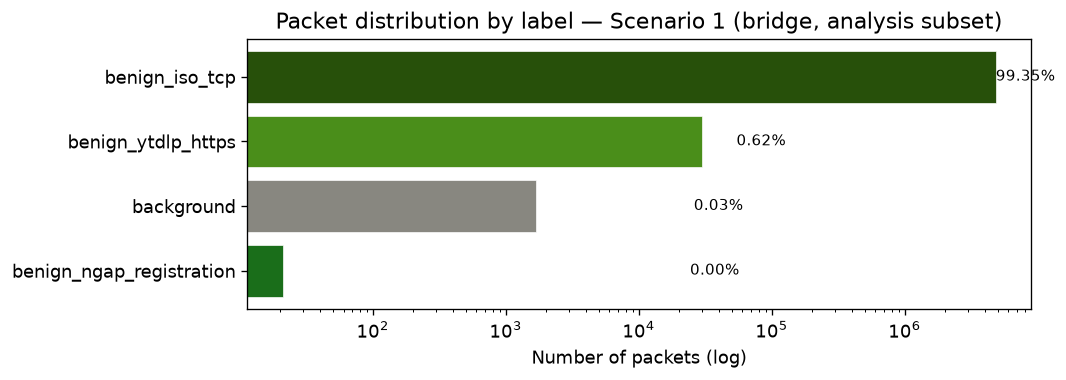

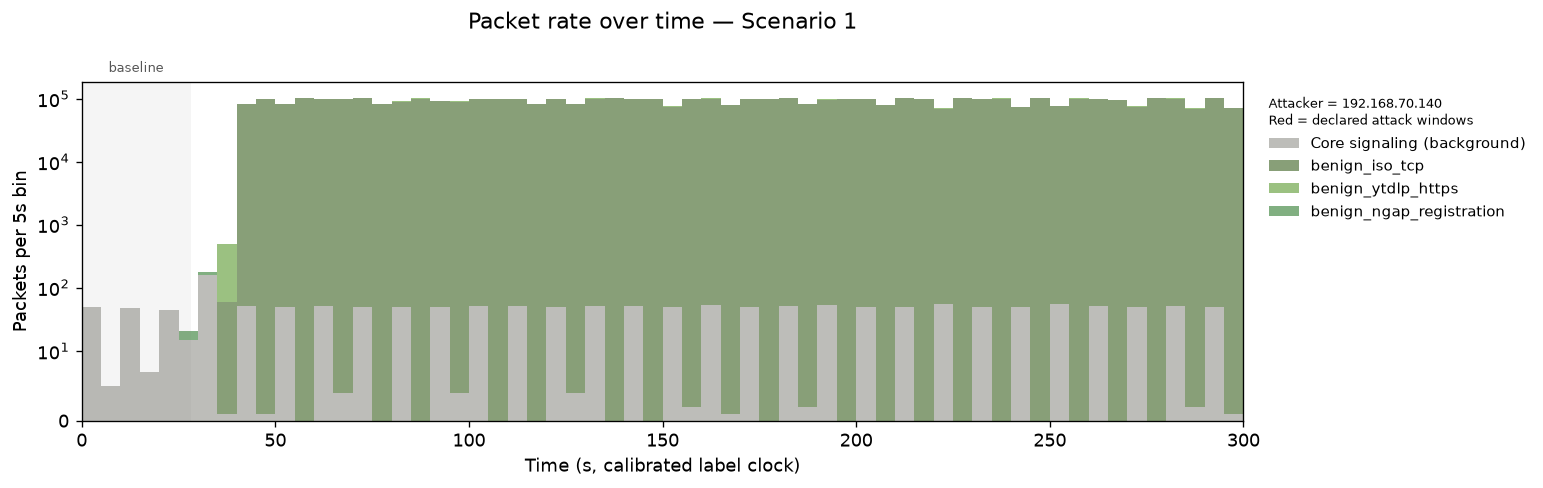


  Classification report (packet-level):


                          precision    recall  f1-score   support

benign_ngap_registration      1.000     1.000     1.000         6
       benign_user_plane      1.000     1.000     1.000    872658

                accuracy                          1.000    872664
               macro avg      1.000     1.000     1.000    872664
            weighted avg      1.000     1.000     1.000    872664



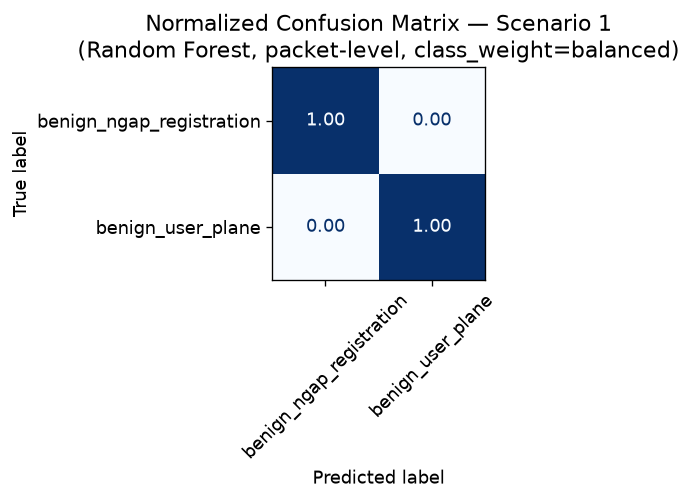

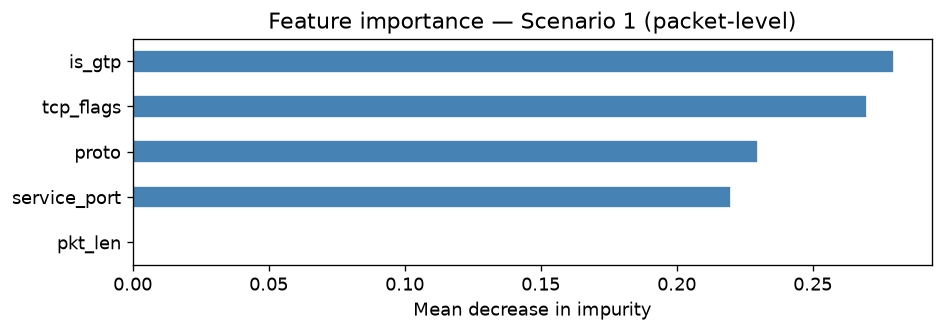


  Frames per protocol (analysis PCAP):


,Frames
HTTP2,1569
NGAP,18
SCTP,57
PFCP,66
GTP,2908865
IP fragments,1936292
Other IP,41
UDP/2152,2908865
ICMP,0
Attacker,0



  Scenario 2


  UDP/2152 packets: 2,881,495  |  with inner IP header decoded: 2,881,427 (100.0%)
  IP fragments: 1,910,792 non-final, 1,910,792 final (packet reassembled there)
  UE address(es) from labels_time.csv: ['10.0.0.2']


  Label clock offset measured: +0.070 s (not applied)
  T0 = first bridge packet +0.000 s   (labels: epoch columns)
  Start offsets before calibration (first attacker packet - declared start):


,proto,declared_start,observed_first,start_offset
label,,,,
attack_portscan,TCP,56.58,57.71,1.13
attack_syn_flood,TCP,96.70,96.77,0.07
attack_udp_flood,UDP,141.80,141.86,0.07
attack_icmp_flood,ICMP,186.89,186.95,0.07
attack_cve_65805,SCTP,237.04,237.12,0.07


... (7 outputs left out)

  Attacker bursts from packet content (gap > 3s splits a burst):


,proto,t_first,t_last,duration_s,packets
0,TCP,57.71,81.23,23.52,49
1,TCP,96.77,126.75,29.98,2435762
2,UDP,141.86,171.85,29.98,4056482
3,ICMP,186.95,216.94,29.98,3025977


  attacker_other: 35 packets, by protocol / ICMP type:


,,packets
proto_inner,icmp_type,
1.0,3.0,35


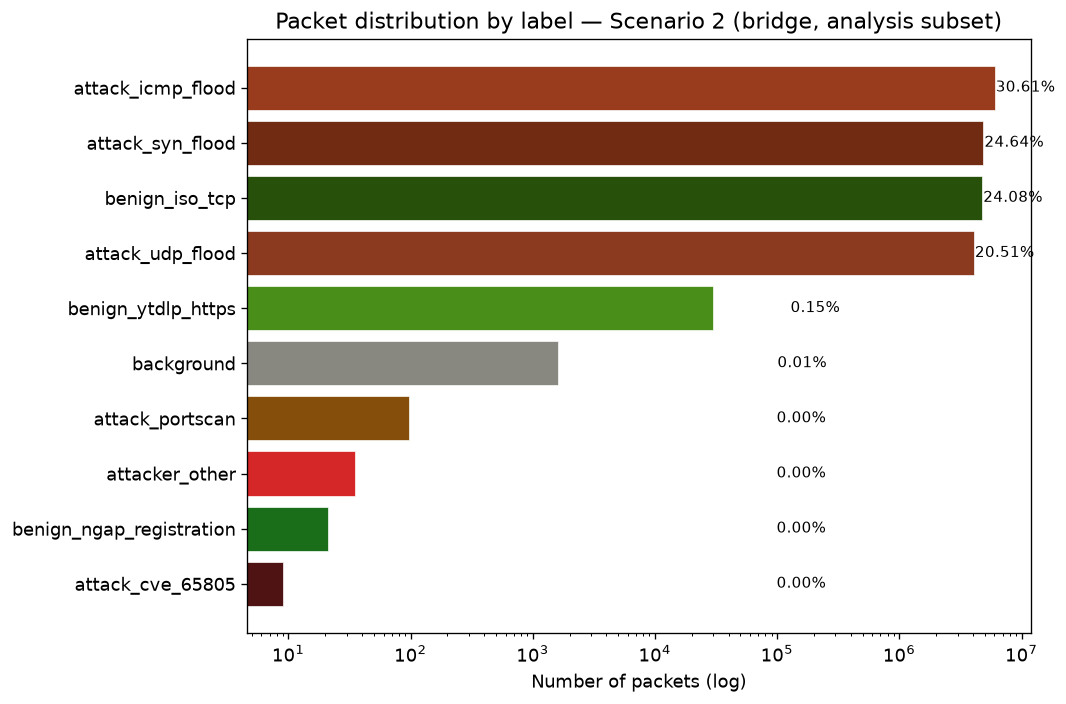

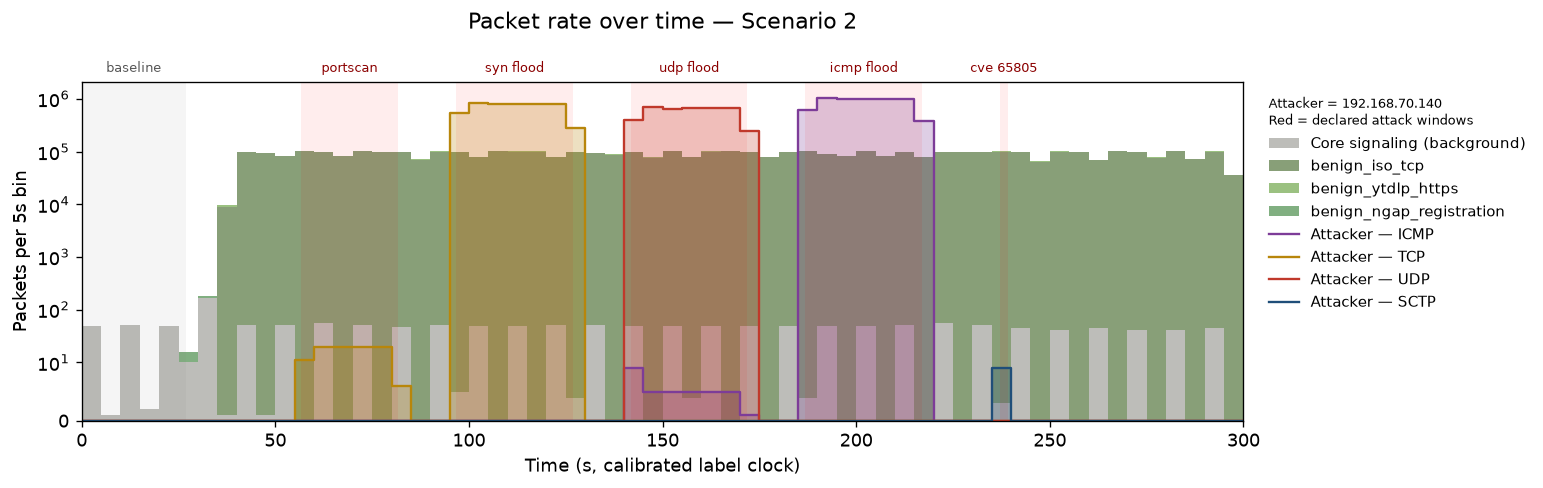

  [note] Leaving out classes with <10 packet-level: attack_cve_65805 (9)



  Classification report (packet-level):


                          precision    recall  f1-score   support

       attack_icmp_flood      1.000     1.000     1.000   1815587
         attack_portscan      0.683     0.966     0.800        29
        attack_syn_flood      1.000     1.000     1.000   1461457
        attack_udp_flood      1.000     1.000     1.000   1216945
benign_ngap_registration      1.000     1.000     1.000         6
       benign_user_plane      1.000     1.000     1.000    864428

                accuracy                          1.000   5358452
               macro avg      0.947     0.994     0.967   5358452
            weighted avg      1.000     1.000     1.000   5358452



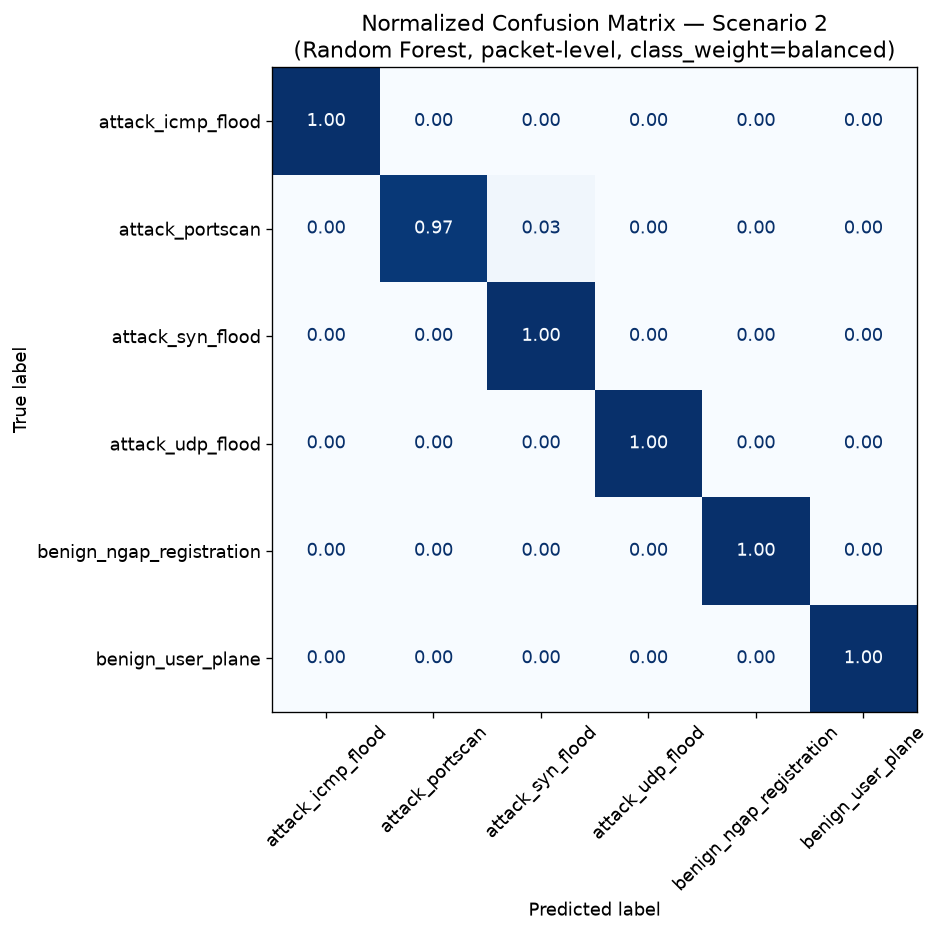

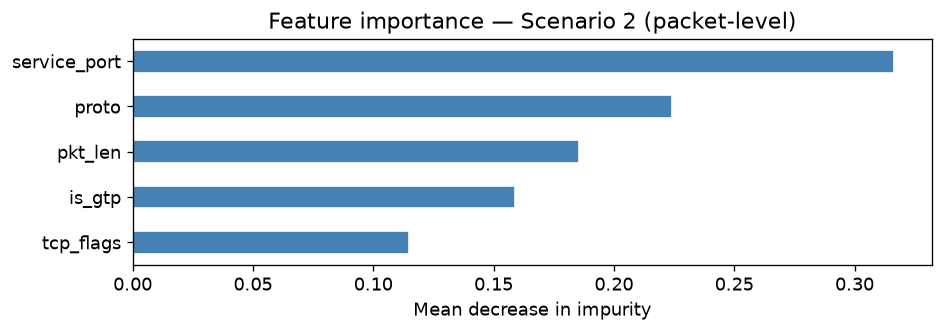


  Frames per protocol (analysis PCAP):


,Frames
HTTP2,1517
NGAP,19
SCTP,61
PFCP,66
GTP,2881434
IP fragments,1910792
Other IP,14980136
UDP/2152,2881495
ICMP,6051989
Attacker,14980101



  Scenario 3


  UDP/2152 packets: 2,984,632  |  with inner IP header decoded: 2,984,564 (100.0%)
  IP fragments: 2,007,651 non-final, 2,007,651 final (packet reassembled there)
  UE address(es) from labels_time.csv: ['10.0.0.2']


  Label clock offset measured: +0.070 s (not applied)
  T0 = first bridge packet +0.000 s   (labels: epoch columns)
  Start offsets before calibration (first attacker packet - declared start):


,proto,declared_start,observed_first,start_offset
label,,,,
attack_portscan,TCP,60.15,61.27,1.12
attack_syn_flood,TCP,90.24,90.31,0.07
attack_udp_flood,UDP,110.31,110.36,0.06
attack_icmp_flood,ICMP,130.39,130.46,0.07
attack_cve_65805,SCTP,210.56,210.65,0.09


... (7 outputs left out)

  Attacker bursts from packet content (gap > 3s splits a burst):


,proto,t_first,t_last,duration_s,packets
0,TCP,61.27,79.79,18.52,39
1,TCP,90.31,120.30,29.99,2364605
2,UDP,110.36,140.35,29.99,3993960
3,ICMP,130.46,160.44,29.98,2960037


  attacker_other: 35 packets, by protocol / ICMP type:


,,packets
proto_inner,icmp_type,
1.0,3.0,35


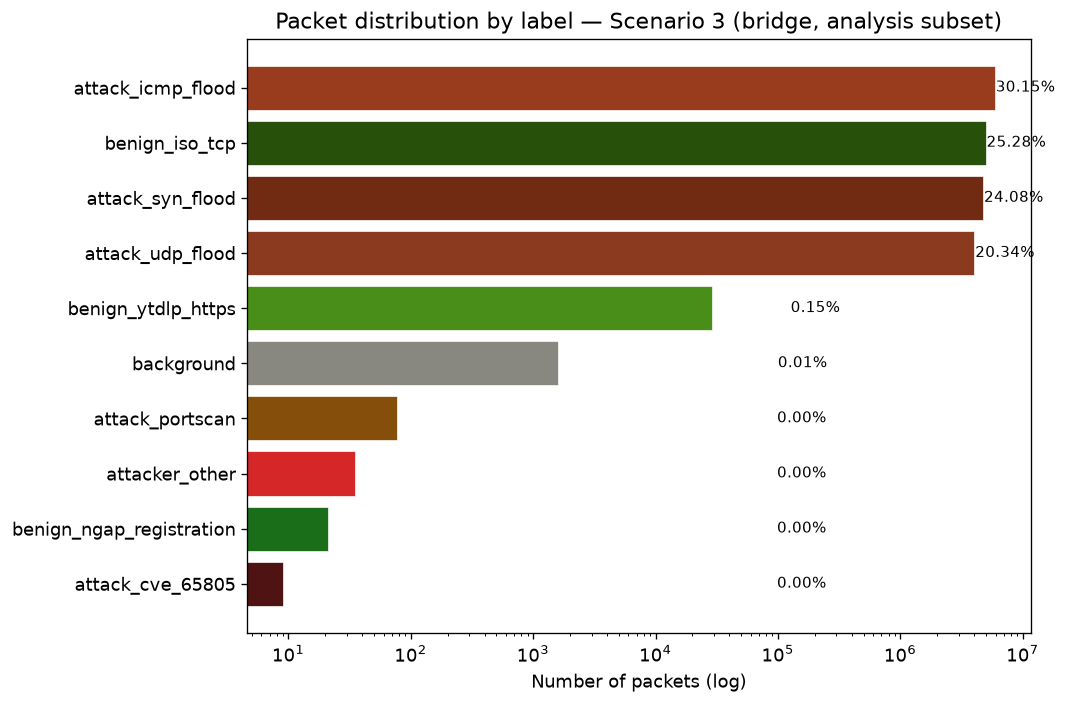

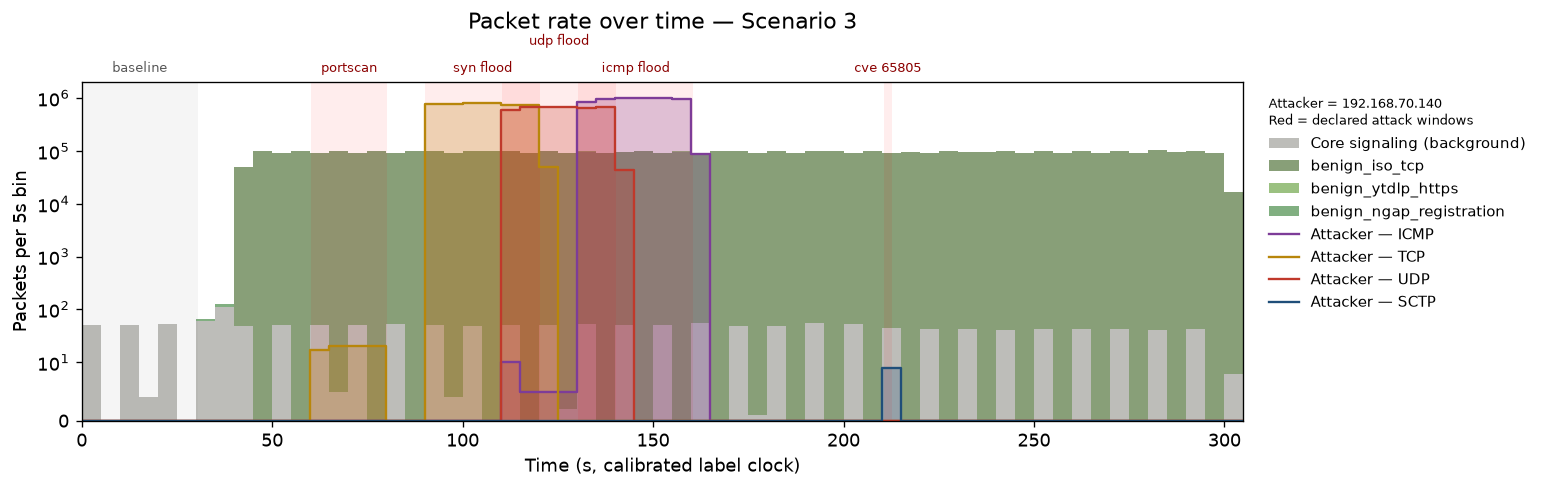

  [note] Leaving out classes with <10 packet-level: attack_cve_65805 (9)



  Classification report (packet-level):


                          precision    recall  f1-score   support

       attack_icmp_flood      1.000     1.000     1.000   1776022
         attack_portscan      0.629     0.957     0.759        23
        attack_syn_flood      1.000     1.000     1.000   1418763
        attack_udp_flood      1.000     1.000     1.000   1198188
benign_ngap_registration      1.000     1.000     1.000         7
       benign_user_plane      1.000     1.000     1.000    895369

                accuracy                          1.000   5288372
               macro avg      0.938     0.993     0.960   5288372
            weighted avg      1.000     1.000     1.000   5288372



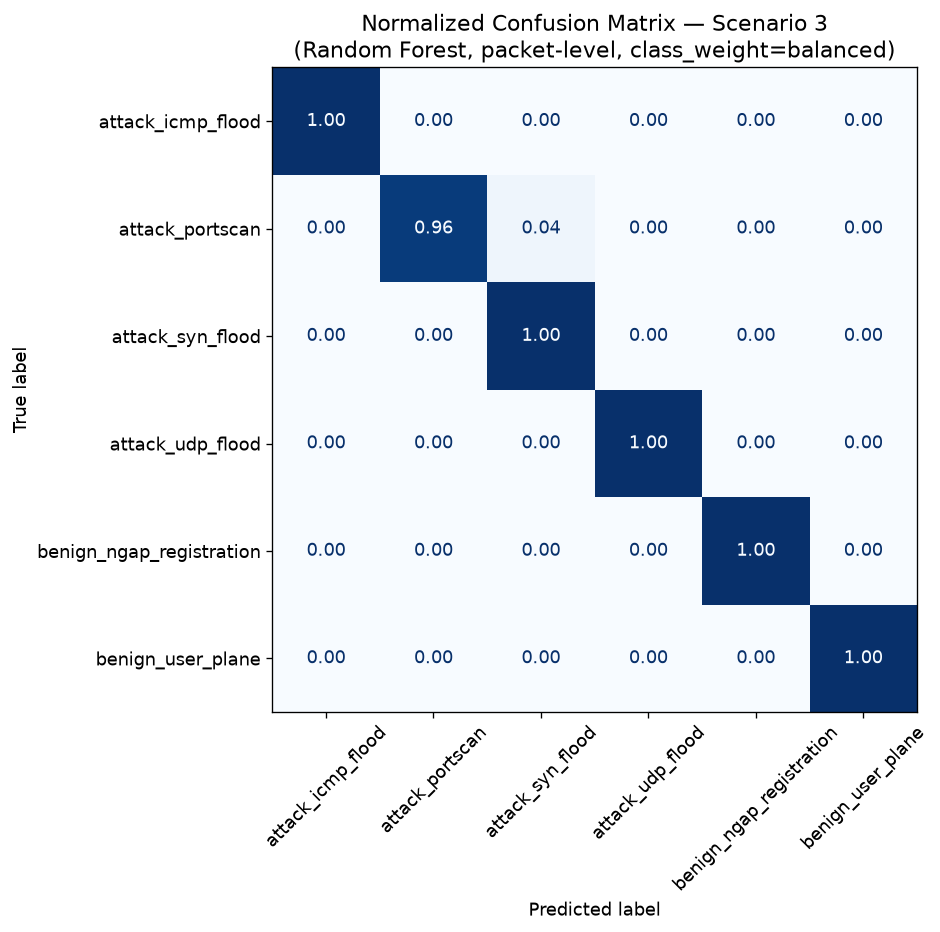

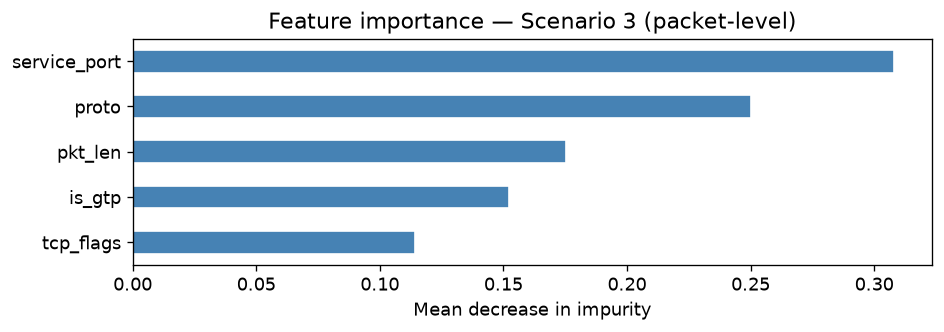


  Frames per protocol (analysis PCAP):


,Frames
HTTP2,1496
NGAP,19
SCTP,57
PFCP,66
GTP,2984571
IP fragments,2007651
Other IP,14643396
UDP/2152,2984632
ICMP,5920109
Attacker,14643365



Time base per scenario:


,T0 source,offset applied (s),labels
1,first bridge packet,0.0,epoch columns
2,first bridge packet,0.0,epoch columns
3,first bridge packet,0.0,epoch columns


In [7]:
all_counts, all_reports, all_protos = {}, {}, {}
pkt_feats, T0, time_info, pkt_sent, UE, pkt_benign = {}, {}, {}, {}, {}, {}

for sc in SCENARIOS:
    n, title = sid(sc), f'Scenario {sid(sc)}'
    print(f'\n{"=" * 60}\n  {title}\n{"=" * 60}')
    if not os.path.exists(pcap_path(sc, 'bridge')):
        print('  [skip] bridge PCAP not found')
        continue

    df = load_packets(sc)
    if df.empty:
        print('  [skip] no packets')
        continue
    UE[n] = ue_ips(sc)
    print(f'  UE address(es) from labels_time.csv: {sorted(UE[n]) or "none"}')

    # -- time base + calibration --
    t0, how = base_t0(sc)
    df['t_rel'] = df['epoch'] - t0
    labels = load_time_labels(sc, t0)
    offset, dvo0 = 0.0, None
    if labels['label'].str.startswith('attack').any() and attacker_sent(df).any():
        offset, dvo0 = estimate_offset(df, labels)
        if labels.attrs['epoch'] or not CALIBRATE_T0:
            print(f'  Label clock offset measured: {offset:+.3f} s (not applied)')
            offset = 0.0
    T0[n] = t0 + offset
    labels = load_time_labels(sc, T0[n])
    time_info[n] = {'T0 source': how, 'offset applied (s)': round(offset, 3),
                    'labels': 'epoch columns' if labels.attrs['epoch'] else 'integer seconds'}
    print(f'  T0 = {how} {offset:+.3f} s   (labels: {time_info[n]["labels"]})')
    if dvo0 is not None:
        print('  Start offsets before calibration (first attacker packet - declared start):')
        display(dvo0[['proto', 'declared_start', 'observed_first', 'start_offset']])

    # -- labels --
    server_map, sni_summary = sni_server_map(sc)
    print(f'  TLS servers mapped to benign classes: {len(server_map)}')
    display(sni_summary.head(10))
    df = assign_labels(df, labels, T0[n], server_map)
    counts = df['label'].value_counts()
    all_counts[n] = counts
    print(f'  Packets: {len(df):,}  |  involving the attacker: {int(df["is_attacker"].sum()):,}')
    print(counts.to_string())

    sent = attacker_sent(df)
    pkt_sent[n] = df.loc[sent, 'label'].value_counts()

    # -- diagnostics --
    print('\n  Legacy time-only labels — share of attacker traffic per label:')
    display(legacy_label_purity(df))
    if labels['label'].str.startswith('attack').any() and sent.any():
        print(f'  Declared vs observed after calibration (packets sent by the attacker, window ± {PKT_MARGIN_S}s):')
        display(declared_vs_observed(df, labels))
        print(f'  Attacker bursts from packet content (gap > {ACTIVITY_GAP_S}s splits a burst):')
        display(attacker_bursts(df))
        other = df[df['label'] == 'attacker_other']
        if len(other):
            print(f'  attacker_other: {len(other):,} packets, by protocol / ICMP type:')
            display(other.groupby(['proto_inner', 'icmp_type'], dropna=False).size().rename('packets').to_frame())

    # -- figures --
    plot_distribution(counts, title, os.path.join(FIGDIR, f'fig_packet_distribution_s{n}.pdf'))
    plot_packet_rate(df, labels, title, os.path.join(FIGDIR, f'fig_packet_rate_analysis_s{n}.pdf'))

    # -- Random Forest --
    if df.attrs.get('frag_unmatched'):
        print(f'  [warn] {df.attrs["frag_unmatched"]:,} non-final fragments without a matching last fragment')
    # N3 frames: UDP/2152 (incl. GTP-U echo / end marker, which carry no UE packet) + first fragments
    pkt_benign[n] = int((~df['is_attacker'] & ((df['gtp_port'] == 1) |
                        (df.get('is_gtp_frag', pd.Series(0, index=df.index)).fillna(0) == 1))).sum())
    pkt_feats[n] = build_features(df[df['frag_head'] == 0])     # one row per IP packet
    if PKT_MERGE_APPS:
        lab = pkt_feats[n]['label'].astype(str)
        pkt_feats[n]['label'] = lab.where(~lab.isin(list(BENIGN_SNI)), PKT_APP_CLASS).astype('category')
    rep = run_rf(pkt_feats[n], PKT_FEATURES, title, 'packet-level', f'_s{n}',
                 'Random Forest, packet-level, class_weight=balanced')
    if rep is not None:
        all_reports[n] = rep

    all_protos[n] = pd.Series(io_counts(ensure_analysis_pcap(sc), PROTO_COUNTS), name='Frames')
    print('\n  Frames per protocol (analysis PCAP):')
    display(all_protos[n].to_frame())
    del df

print('\nTime base per scenario:')
display(pd.DataFrame(time_info).T)

### Cross-scenario generalization (packet level): train S2 → test S3

  [note] Leaving out classes with <10 packets: attack_cve_65805 (9)


  [note] Leaving out classes with <10 packets: attack_cve_65805 (9)


                          precision    recall  f1-score   support

       attack_icmp_flood      1.000     1.000     1.000   5920074
         attack_portscan      0.679     0.987     0.804        77
        attack_syn_flood      1.000     1.000     1.000   4729210
        attack_udp_flood      1.000     1.000     1.000   3993960
benign_ngap_registration      1.000     1.000     1.000        21
       benign_user_plane      1.000     1.000     1.000   2984564

                accuracy                          1.000  17627906
               macro avg      0.946     0.998     0.967  17627906
            weighted avg      1.000     1.000     1.000  17627906



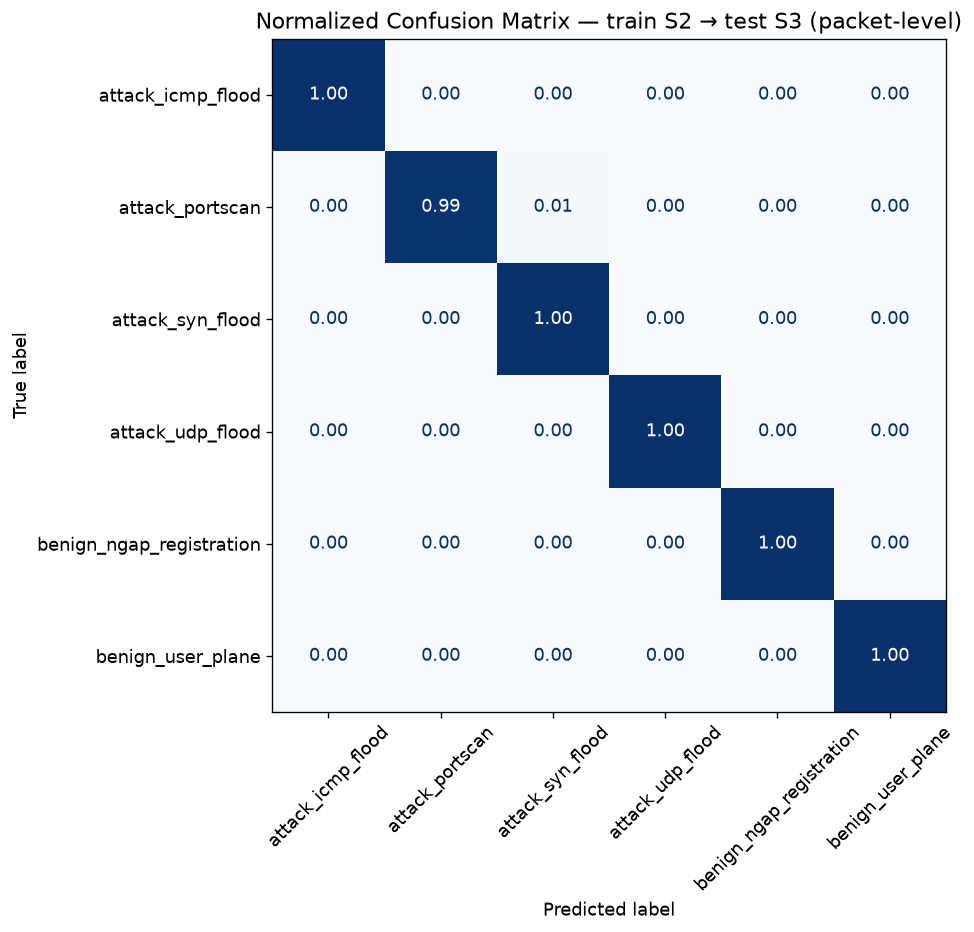

In [8]:
if '2' in pkt_feats and '3' in pkt_feats:
    cross_pkt_report = run_cross(pkt_feats['2'], pkt_feats['3'], PKT_FEATURES,
                                 'train S2 → test S3 (packet-level)', 'packets', '_cross_s2_s3')
else:
    print('[skip] needs scenarios 2 and 3')

## 4. N2 check — NGAP messages per scenario

In [9]:
n2_summary = {}
for sc in SCENARIOS:
    n, n2 = sid(sc), pcap_path(sc, 'n2')
    if not os.path.exists(n2) or n not in T0:
        continue
    out = tshark('-r', n2, '-Y', 'ngap', '-T', 'fields', '-E', 'separator=/t', '-E', 'occurrence=f',
                 '-e', 'frame.time_epoch', '-e', 'ip.src', '-e', 'ip.dst', '-e', 'ngap.procedureCode',
                 '-e', '_ws.col.Info')
    msgs = (pd.read_csv(StringIO(out), sep='\t', header=None, quoting=3,
                        names=['epoch', 'src', 'dst', 'procedureCode', 'info'])
            if out.strip() else pd.DataFrame(columns=['epoch', 'src', 'dst', 'procedureCode', 'info']))
    labels = load_time_labels(sc, T0[n])
    msgs['t'] = (msgs['epoch'].astype(float) - T0[n]).round(2)
    msgs['window'] = ''
    for lbl in ('benign_ngap_registration', 'attack_cve_65805'):
        msgs.loc[_windows(msgs['t'].to_numpy(), labels, lbl, PKT_MARGIN_S), 'window'] = lbl
    n2_summary[n] = {'N2 packets': packet_count(n2), 'NGAP messages': len(msgs),
                     'in registration window': int((msgs['window'] == 'benign_ngap_registration').sum()),
                     'in CVE window': int((msgs['window'] == 'attack_cve_65805').sum())}
    print(f'S{n}: {len(msgs)} NGAP messages')
    if len(msgs):
        display(msgs[['t', 'src', 'dst', 'procedureCode', 'info', 'window']].head(30))
display(pd.DataFrame(n2_summary).T)

S1: 16 NGAP messages


,t,src,dst,procedureCode,info,window
0,28.11,192.168.70.160,192.168.70.132,46,UplinkNASTransport,benign_ngap_registration
1,28.11,192.168.70.132,192.168.70.160,4,"SACK (Ack=0, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
2,28.31,192.168.70.132,192.168.70.160,41,UEContextReleaseCommand,benign_ngap_registration
3,28.32,192.168.70.160,192.168.70.132,41,"SACK (Ack=1, Arwnd=106496) , UEContextReleaseC...",benign_ngap_registration
4,34.71,192.168.70.160,192.168.70.132,15,"InitialUEMessage, Registration request",benign_ngap_registration
5,34.72,192.168.70.132,192.168.70.160,4,"SACK (Ack=2, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
6,34.72,192.168.70.160,192.168.70.132,46,"SACK (Ack=2, Arwnd=106496) , UplinkNASTranspor...",benign_ngap_registration
7,34.73,192.168.70.132,192.168.70.160,4,"SACK (Ack=3, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
8,34.73,192.168.70.160,192.168.70.132,46,"SACK (Ack=3, Arwnd=106496) , UplinkNASTransport",benign_ngap_registration
9,34.73,192.168.70.132,192.168.70.160,14,"SACK (Ack=4, Arwnd=106496) , InitialContextSet...",benign_ngap_registration


S2: 17 NGAP messages


,t,src,dst,procedureCode,info,window
0,26.86,192.168.70.160,192.168.70.132,46,UplinkNASTransport,benign_ngap_registration
1,26.86,192.168.70.132,192.168.70.160,4,"SACK (Ack=0, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
2,27.07,192.168.70.132,192.168.70.160,41,UEContextReleaseCommand,benign_ngap_registration
3,27.08,192.168.70.160,192.168.70.132,41,"SACK (Ack=1, Arwnd=106496) , UEContextReleaseC...",benign_ngap_registration
4,33.73,192.168.70.160,192.168.70.132,15,"InitialUEMessage, Registration request",benign_ngap_registration
5,33.74,192.168.70.132,192.168.70.160,4,"SACK (Ack=2, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
6,33.74,192.168.70.160,192.168.70.132,46,"SACK (Ack=2, Arwnd=106496) , UplinkNASTranspor...",benign_ngap_registration
7,33.75,192.168.70.132,192.168.70.160,4,"SACK (Ack=3, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
8,33.75,192.168.70.160,192.168.70.132,46,"SACK (Ack=3, Arwnd=106496) , UplinkNASTransport",benign_ngap_registration
9,33.76,192.168.70.132,192.168.70.160,14,"SACK (Ack=4, Arwnd=106496) , InitialContextSet...",benign_ngap_registration


S3: 17 NGAP messages


,t,src,dst,procedureCode,info,window
0,30.49,192.168.70.160,192.168.70.132,46,UplinkNASTransport,benign_ngap_registration
1,30.49,192.168.70.132,192.168.70.160,4,"SACK (Ack=0, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
2,30.70,192.168.70.132,192.168.70.160,41,UEContextReleaseCommand,benign_ngap_registration
3,30.71,192.168.70.160,192.168.70.132,41,"SACK (Ack=1, Arwnd=106496) , UEContextReleaseC...",benign_ngap_registration
4,37.16,192.168.70.160,192.168.70.132,15,"InitialUEMessage, Registration request",benign_ngap_registration
5,37.17,192.168.70.132,192.168.70.160,4,"SACK (Ack=2, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
6,37.17,192.168.70.160,192.168.70.132,46,"SACK (Ack=2, Arwnd=106496) , UplinkNASTranspor...",benign_ngap_registration
7,37.18,192.168.70.132,192.168.70.160,4,"SACK (Ack=3, Arwnd=106496) , DownlinkNASTransp...",benign_ngap_registration
8,37.18,192.168.70.160,192.168.70.132,46,"SACK (Ack=3, Arwnd=106496) , UplinkNASTransport",benign_ngap_registration
9,37.18,192.168.70.132,192.168.70.160,14,"SACK (Ack=4, Arwnd=106496) , InitialContextSet...",benign_ngap_registration


,N2 packets,NGAP messages,in registration window,in CVE window
1,57,16,16,0
2,135,17,16,1
3,129,17,16,1


## 5. Bridge PCAP — packets per class, attack timing and packet rate (paper figures)


  Scenario 1 — bridge PCAP


  Label clock = frame.time_relative -0.000 s


Benign (UE1, GTP-U, N3)               4,845,157
Attacker, outside declared windows            0
Replies to the attacker                       0
Other (N6, core signaling)            2,792,521
Total                                 7,637,678

  Scenario 2 — bridge PCAP
  Label clock = frame.time_relative -0.000 s


Benign (UE1, GTP-U, N3)                4,792,226
attack_portscan                               49
attack_syn_flood                       2,435,762
attack_udp_flood                       4,056,482
attack_icmp_flood                      3,025,977
attack_cve_65805                               4
Attacker, outside declared windows             0
Replies to the attacker                5,461,827
Other (N6, core signaling)             2,765,019
Total                                 22,537,346

  Attacker bursts (1-s bins, calibrated clock):


,proto,observed_start,observed_end,packets
0,TCP,57.0,82.0,49
1,TCP,96.0,127.0,2435762
2,UDP,141.0,172.0,4056482
3,ICMP,186.0,217.0,3025977
4,SCTP,237.0,238.0,4


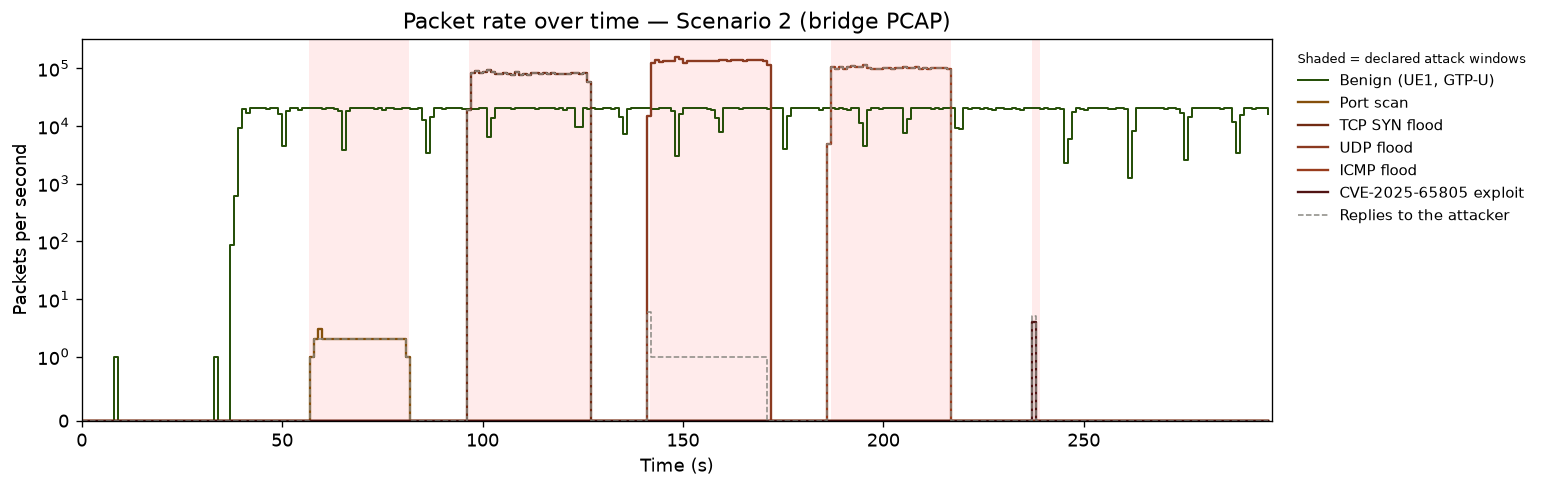


  Scenario 3 — bridge PCAP


  Label clock = frame.time_relative -0.000 s


Benign (UE1, GTP-U, N3)                4,992,222
attack_portscan                               39
attack_syn_flood                       2,364,605
attack_udp_flood                       3,993,960
attack_icmp_flood                      2,960,037
attack_cve_65805                               4
Attacker, outside declared windows             0
Replies to the attacker                5,324,720
Other (N6, core signaling)             2,860,362
Total                                 22,495,949

  Attacker bursts (1-s bins, calibrated clock):


,proto,observed_start,observed_end,packets
0,TCP,61.0,80.0,39
1,TCP,90.0,121.0,2364605
2,UDP,110.0,141.0,3993960
3,ICMP,130.0,161.0,2960037
4,SCTP,210.0,211.0,4


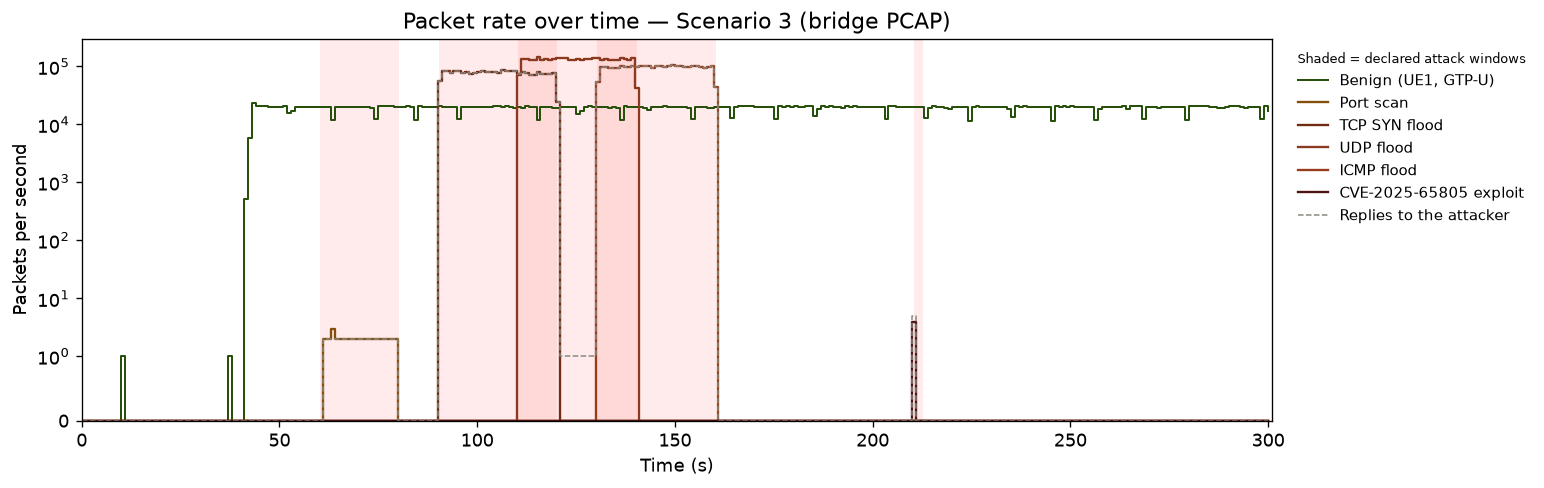


Packets by class across scenarios (bridge PCAP):


,S1,S2,S3
"Benign (UE1, GTP-U, N3)",4845157,4792226,4992222
attack_portscan,<NA>,49,39
attack_syn_flood,<NA>,2435762,2364605
attack_udp_flood,<NA>,4056482,3993960
attack_icmp_flood,<NA>,3025977,2960037
attack_cve_65805,<NA>,4,4
"Attacker, outside declared windows",0,0,0
Replies to the attacker,0,5461827,5324720
"Other (N6, core signaling)",2792521,2765019,2860362
Total,7637678,22537346,22495949


S1 — frames per class, bridge vs packet-level labels (attacks: sent by the attacker) (OK):


,bridge,packet-level,diff
"Benign (UE1, GTP-U, N3)",4845157,4845157,0


S2 — frames per class, bridge vs packet-level labels (attacks: sent by the attacker) (OK):


,bridge,packet-level,diff
attack_portscan,49,49,0
attack_syn_flood,2435762,2435762,0
attack_udp_flood,4056482,4056482,0
attack_icmp_flood,3025977,3025977,0
attack_cve_65805,4,4,0
"Benign (UE1, GTP-U, N3)",4792226,4792226,0


S3 — frames per class, bridge vs packet-level labels (attacks: sent by the attacker) (OK):


,bridge,packet-level,diff
attack_portscan,39,39,0
attack_syn_flood,2364605,2364605,0
attack_udp_flood,3993960,3993960,0
attack_icmp_flood,2960037,2960037,0
attack_cve_65805,4,4,0
"Benign (UE1, GTP-U, N3)",4992222,4992222,0


In [10]:
CLASS_NAME = {'attack_portscan': 'Port scan', 'attack_syn_flood': 'TCP SYN flood',
              'attack_udp_flood': 'UDP flood', 'attack_icmp_flood': 'ICMP flood',
              'attack_cve_65805': 'CVE-2025-65805 exploit'}
BENIGN_ROW = 'Benign (UE1, GTP-U, N3)'
CLASS_ORDER = ([BENIGN_ROW] + list(CLASS_NAME)
               + ['Attacker, outside declared windows', 'Replies to the attacker',
                  'Other (N6, core signaling)', 'Total'])


def bridge_filters(labels, shift):
    # `shift` converts label time (relative to calibrated T0) to frame.time_relative.
    K, m = KALI_IP, PKT_MARGIN_S
    f = {
        'Total':                   'frame',
        BENIGN_ROW:                (f'!(ip.addr#1=={K}) && (udp.port#1==2152 || '
                                    f'(ip.flags.mf#1==1 && !udp && ip.addr#1=={UPF_IP}))'),
        'Replies to the attacker': f'ip.dst#1=={K}',
        'Sent by the attacker':    f'ip.src#1=={K}',
    }
    for p, name in PROTO_NAME.items():
        f[f'Attacker {name}'] = f'ip.src#1=={K} && ip.proto#1=={p}'
    win = {}
    for _, r in labels[labels['label'].str.startswith('attack')].iterrows():
        lo, hi = max(r['t_start'] + shift - m, 0), r['t_end'] + shift + m
        win.setdefault(r['label'], []).append(
            f'(frame.time_relative>={lo:.6f} && frame.time_relative<={hi:.6f})')
    for lbl, w in win.items():
        f[lbl] = f'ip.src#1=={K} && ip.proto#1=={ATTACK_PROTO[lbl]} && ({" || ".join(w)})'
    return f


def tshark_series(pcap, filters, interval=1):
    out = tshark('-r', pcap, '-q', '-z', f'io,stat,{interval},' + ','.join(filters.values()))
    rows = []
    for line in out.splitlines():
        if '<>' in line:
            parts = [p.strip() for p in line.split('|') if p.strip()]
            start = parts[0].split('<>')[0].strip()
            if start.lower() == 'dur':
                continue
            rows.append([float(start)] + [int(v) for v in parts[1::2]])
    return pd.DataFrame(rows, columns=['t'] + list(filters)).set_index('t')


def bursts_from_series(s, gap=ACTIVITY_GAP_S):
    t = s.index[s.to_numpy() > 0].to_numpy()
    if t.size == 0:
        return []
    brk = np.where(np.diff(t) > gap)[0]
    return [(t[a], t[b] + 1, int(s.loc[t[a]:t[b]].sum()))
            for a, b in zip(np.r_[0, brk + 1], np.r_[brk, len(t) - 1])]


def plot_bridge_rate(series, labels, shift, title, path):
    fig, ax = plt.subplots(figsize=(13, 4.2))
    x = series.index.to_numpy() - shift                     # calibrated label clock
    ax.step(x, series[BENIGN_ROW], where='post', color='#27500A', lw=1.2, label='Benign (UE1, GTP-U)')
    for lbl in [c for c in series.columns if c.startswith('attack_')]:
        ax.step(x, series[lbl], where='post', color=COLOR.get(lbl, '#444444'), lw=1.4,
                label=CLASS_NAME.get(lbl, lbl))
    ax.step(x, series['Replies to the attacker'], where='post', color='#888780', lw=0.9, ls='--',
            label='Replies to the attacker')
    for _, r in labels[labels['label'].str.startswith('attack')].iterrows():
        ax.axvspan(r['t_start'], r['t_end'], alpha=0.08, color='red', lw=0)
    ax.set_yscale('symlog', linthresh=1)
    ax.set_xlim(max(x[0], 0), x[-1] + 1)
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Packets per second')
    ax.set_title(f'Packet rate over time — {title} (bridge PCAP)')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9,
              title='Shaded = declared attack windows', title_fontsize=8, alignment='left')
    plt.tight_layout()
    fig.savefig(path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


bridge_counts, bridge_series, consistency, bridge_shift = {}, {}, {}, {}
for sc in SCENARIOS:
    n, bridge = sid(sc), pcap_path(sc, 'bridge')
    if not os.path.exists(bridge):
        continue
    print(f'\n{"=" * 60}\n  Scenario {n} — bridge PCAP\n{"=" * 60}')
    t_bridge = first_epoch(bridge)
    t0       = T0.get(n, t_bridge)
    labels   = load_time_labels(sc, t0)
    shift    = t0 - t_bridge
    print(f'  Label clock = frame.time_relative {-shift:+.3f} s')

    s = tshark_series(bridge, bridge_filters(labels, shift))
    bridge_series[n] = s
    bridge_shift[n] = shift
    tot = s.sum()
    attack_cols = [c for c in s.columns if c.startswith('attack_')]
    counts = pd.Series({BENIGN_ROW: tot[BENIGN_ROW]}, dtype='int64')
    for c in attack_cols:
        counts[c] = tot[c]
    counts['Attacker, outside declared windows'] = tot['Sent by the attacker'] - tot[attack_cols].sum()
    counts['Replies to the attacker'] = tot['Replies to the attacker']
    counts['Other (N6, core signaling)'] = (tot['Total'] - tot[BENIGN_ROW] - tot['Sent by the attacker']
                                           - tot['Replies to the attacker'])
    counts['Total'] = tot['Total']
    bridge_counts[n] = counts
    print(counts.map('{:,}'.format).to_string())

    rows = []
    for p in PROTO_NAME.values():
        for a, b, k in bursts_from_series(s[f'Attacker {p}']):
            rows.append({'proto': p, 'observed_start': round(a - shift, 2),
                         'observed_end': round(b - shift, 2), 'packets': k})
    if rows:
        print(f'\n  Attacker bursts (1-s bins, calibrated clock):')
        display(pd.DataFrame(rows).sort_values('observed_start').reset_index(drop=True))
    if counts['Attacker, outside declared windows'] > 0:
        print(f'  [warn] {counts["Attacker, outside declared windows"]:,} attacker packets outside '
              f'the windows ± {PKT_MARGIN_S}s')

    if n in pkt_sent:
        consistency[n] = pd.DataFrame({'bridge': counts.reindex(attack_cols),
                                       'packet-level': pkt_sent[n].reindex(attack_cols)}).fillna(0).astype('int64')
        consistency[n].loc[BENIGN_ROW] = [counts[BENIGN_ROW], pkt_benign.get(n, 0)]
        consistency[n]['diff'] = consistency[n]['bridge'] - consistency[n]['packet-level']
    if attack_cols:
        plot_bridge_rate(s, labels, shift, f'Scenario {n}', os.path.join(FIGDIR, f'fig_packet_rate_detail_s{n}.pdf'))


def bridge_table():
    B = pd.DataFrame(bridge_counts)
    return B.reindex([c for c in CLASS_ORDER if c in B.index])


if bridge_counts:
    print('\nPackets by class across scenarios (bridge PCAP):')
    display(bridge_table().astype('Int64').rename(columns=lambda c: f'S{c}'))
for n, c in consistency.items():
    print(f'S{n} — frames per class, bridge vs packet-level labels (attacks: sent by the attacker) '
          f'({"OK" if (c["diff"] == 0).all() else "MISMATCH"}):')
    display(c)

### 5b. Packet-rate figure for the paper

Scenario 1: counting packets per second in the bridge PCAP...


Scenario 2: counting packets per second in the bridge PCAP...


Scenario 3: counting packets per second in the bridge PCAP...


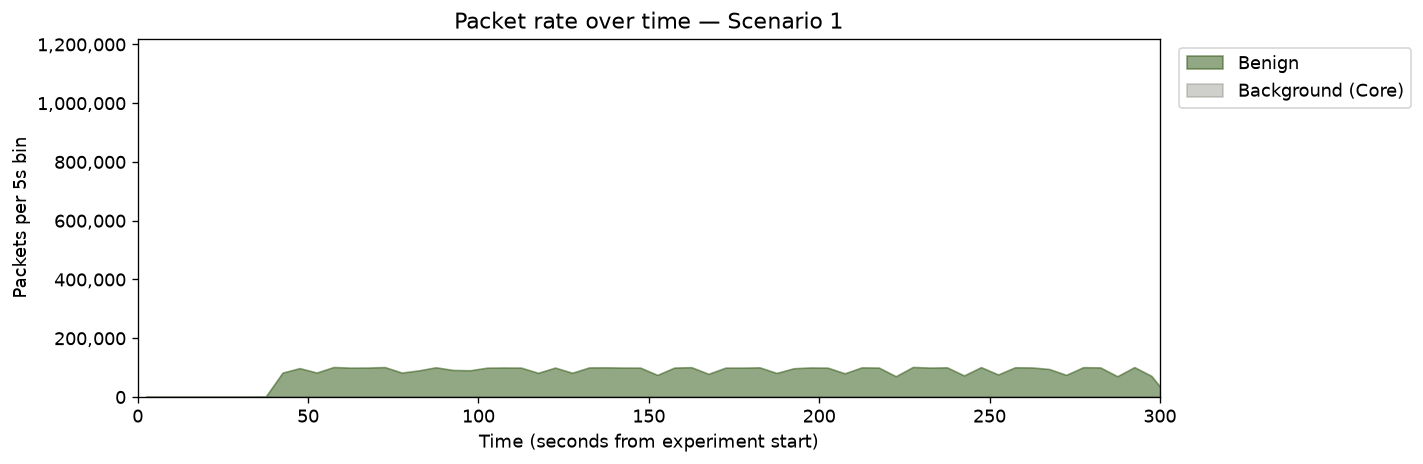

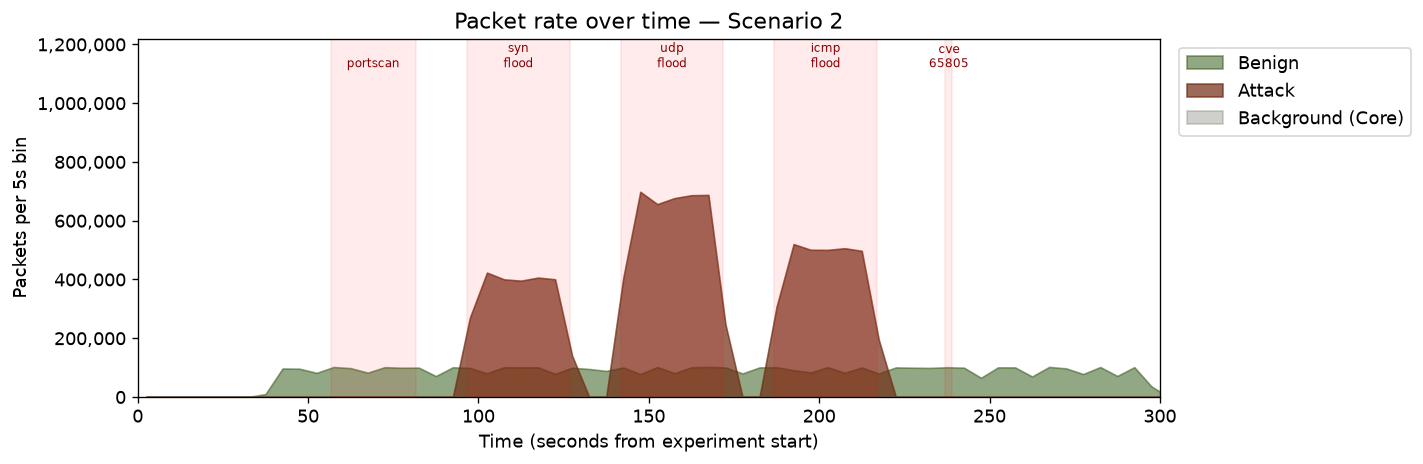

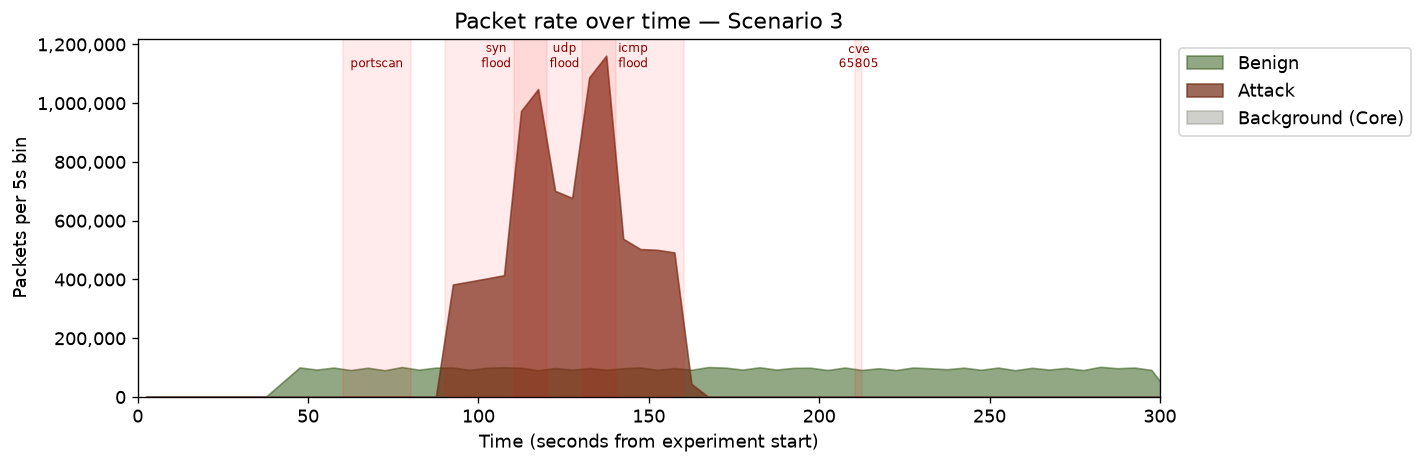

In [ ]:
RATE_BIN_S  = 5
RATE_YSCALE = 'linear'      
RATE_SHARED_Y = True        
RATE_PER_SECOND = False     
RATE_STYLE  = [             
    ('benign',     'Benign',            '#27500A', 0.5),
    ('attack',     'Attack',            '#712B13', 0.7),
    ('background', 'Background (Core)', '#888780', 0.4),
]


def _io_series(pcap, filters, interval=1):
    out = tshark('-r', pcap, '-q', '-z', f'io,stat,{interval},' + ','.join(filters.values()))
    rows = []
    for line in out.splitlines():
        if '<>' in line:
            parts = [p.strip() for p in line.split('|') if p.strip()]
            start = parts[0].split('<>')[0].strip()
            if start.lower() != 'dur':
                rows.append([float(start)] + [int(v) for v in parts[1::2]])
    return pd.DataFrame(rows, columns=['t'] + list(filters)).set_index('t')


def rate_series(scenario_id):
    K = KALI_IP
    return _io_series(pcap_path(scenario_id, 'bridge'), {
        'benign':     f'!(ip.addr#1=={K}) && (udp.port#1==2152 || (ip.flags.mf#1==1 && !udp && ip.addr#1=={UPF_IP}))',
        'attack':     f'ip.src#1=={K}',
        'background': f'!(ip.addr#1=={K}) && (http2 || pfcp || sctp)',
    })


def bin_rate(series, shift):
    t = series.index.to_numpy() - shift                    # seconds on the label clock
    g = series.groupby(np.floor(t / RATE_BIN_S) * RATE_BIN_S).sum()
    bins = np.arange(0, max(g.index.max(), 300) + RATE_BIN_S, RATE_BIN_S)
    g = g.reindex(bins, fill_value=0)                      # correction 1: explicit zeros
    return g / RATE_BIN_S if RATE_PER_SECOND else g


def plot_rate_v2(g, labels, title, path, ymax=None):

    x = g.index.to_numpy() + RATE_BIN_S / 2               # each bin drawn at its center, so the
                                                          # rise/fall is centered on the real edge
    fig, ax = plt.subplots(figsize=(12, 4))
    for col, name, color, alpha in RATE_STYLE:
        if g[col].any():
            ax.fill_between(x, g[col].to_numpy(), alpha=alpha, color=color, label=name)
    if RATE_YSCALE == 'symlog':
        ax.set_yscale('symlog', linthresh=10)
    ax.set_ylim(0, ymax)                                   

    ymax = ax.get_ylim()[1] or 1
    for _, row in labels[labels['label'].str.startswith('attack')].iterrows():
        mid = (row['t_start'] + row['t_end']) / 2
        ax.axvspan(row['t_start'], row['t_end'], alpha=0.08, color='red')   
        ax.text(mid, ymax * (0.55 if RATE_YSCALE == 'symlog' else 0.92),
                row['label'].replace('attack_', '').replace('_', '\n'),
                ha='center', fontsize=7, color='darkred')

    ax.set_xlabel('Time (seconds from experiment start)')
    ax.set_ylabel('Packets per second' if RATE_PER_SECOND else f'Packets per {RATE_BIN_S}s bin')
    ax.set_title(f'Packet rate over time — {title}')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))                    
    ax.set_xlim(0, 300)
    plt.tight_layout()
    fig.savefig(path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


rate_bins, rate_labels = {}, {}
for sc in SCENARIOS:
    n, bridge = sid(sc), pcap_path(sc, 'bridge')
    if not os.path.exists(bridge):
        continue
    t0, _ = base_t0(sc) if 'T0' not in globals() or sid(sc) not in T0 else (T0[sid(sc)], '')
    rate_labels[n] = load_time_labels(sc, t0)
    print(f'Scenario {n}: counting packets per second in the bridge PCAP...')
    rate_bins[n] = bin_rate(rate_series(sc), t0 - first_epoch(bridge))

# Shared y limit: highest bin of any scenario (+5%), so S2 and S3 use the same scale
y_top = 1.05 * max(g.max().max() for g in rate_bins.values()) if RATE_SHARED_Y and rate_bins else None
for n, g in rate_bins.items():
    plot_rate_v2(g, rate_labels[n], f'Scenario {n}', os.path.join(FIGDIR, f'fig_packet_rate_s{n}.pdf'), y_top)

### 5c. Timeline table for the paper

In [12]:
def capture_duration(pcap):
    out = subprocess.run(['capinfos', '-u', '-M', pcap], capture_output=True, text=True).stdout
    m = re.search(r'Capture duration:\s*([\d.]+)', out)
    return float(m.group(1)) if m else np.nan


PHASES = [('UE re-registration (NGAP)', None),
          ('Benign: file download + streaming', 'benign_iso_tcp'),
          ('Port scan', 'attack_portscan'),
          ('TCP SYN flood', 'attack_syn_flood'),
          ('UDP flood', 'attack_udp_flood'),
          ('ICMP flood', 'attack_icmp_flood'),
          ('Exploit CVE-2025-65805', 'attack_cve_65805')]

timeline, durations = {}, {}
for sc in SCENARIOS:
    n = sid(sc)
    if n not in T0:
        continue
    labels = load_time_labels(sc, T0[n])
    col = {}
    out = tshark('-r', pcap_path(sc, 'n2'), '-Y', f'ngap and ip.addr=={GNB_IP}',
                 '-T', 'fields', '-e', 'frame.time_epoch')
    t_ngap = np.array([float(v) for v in out.split()]) - T0[n]
    col[PHASES[0][0]] = (t_ngap.min(), t_ngap.max()) if t_ngap.size else None
    for name, lbl in PHASES[1:]:
        r = labels[labels['label'] == lbl]
        col[name] = (r['t_start'].min(), r['t_end'].max()) if len(r) else None
    timeline[f'S{n}'] = col
    durations[f'S{n}'] = capture_duration(pcap_path(sc, 'bridge'))

fmt = lambda v: '---' if v is None else f'{v[0]:.1f}--{v[1]:.1f}'
T = pd.DataFrame({k: {p: fmt(v) for p, v in c.items()} for k, c in timeline.items()})
display(T)
print('Capture duration (s): ' + ', '.join(f'{k} {v:.1f}' for k, v in durations.items()))
for k, c in timeline.items():
    b = c['Benign: file download + streaming']
    if b:
        print(f'{k}: benign user-plane traffic lasts {b[1] - b[0]:.1f} s')

print('\n% --- Timeline table (s from the first packet of the bridge PCAP) ---')
for p in T.index:
    print(f'{p} & ' + ' & '.join(T.loc[p, c] for c in T.columns) + ' \\\\ \\hline')
s3 = timeline.get('S3', {})
syn, udp, icmp = (s3.get(k) for k in ('TCP SYN flood', 'UDP flood', 'ICMP flood'))
if syn and udp and icmp:
    print(f'% S3 overlaps: SYN/UDP {max(syn[0], udp[0]):.1f}--{min(syn[1], udp[1]):.1f} s ; '
          f'UDP/ICMP {max(udp[0], icmp[0]):.1f}--{min(udp[1], icmp[1]):.1f} s')

,S1,S2,S3
UE re-registration (NGAP),28.1--34.8,26.9--33.8,30.5--37.2
Benign: file download + streaming,38.8--298.0,37.4--296.7,41.0--300.8
Port scan,---,56.6--81.7,60.2--80.2
TCP SYN flood,---,96.7--126.8,90.2--120.2
UDP flood,---,141.8--171.9,110.3--140.3
ICMP flood,---,186.9--217.0,130.4--160.5
Exploit CVE-2025-65805,---,237.0--239.1,210.6--212.7


Capture duration (s): S1 298.6, S2 296.8, S3 300.8
S1: benign user-plane traffic lasts 259.1 s
S2: benign user-plane traffic lasts 259.3 s
S3: benign user-plane traffic lasts 259.8 s

% --- Timeline table (s from the first packet of the bridge PCAP) ---
UE re-registration (NGAP) & 28.1--34.8 & 26.9--33.8 & 30.5--37.2 \\ \hline
Benign: file download + streaming & 38.8--298.0 & 37.4--296.7 & 41.0--300.8 \\ \hline
Port scan & --- & 56.6--81.7 & 60.2--80.2 \\ \hline
TCP SYN flood & --- & 96.7--126.8 & 90.2--120.2 \\ \hline
UDP flood & --- & 141.8--171.9 & 110.3--140.3 \\ \hline
ICMP flood & --- & 186.9--217.0 & 130.4--160.5 \\ \hline
Exploit CVE-2025-65805 & --- & 237.0--239.1 & 210.6--212.7 \\ \hline
% S3 overlaps: SYN/UDP 110.3--120.2 s ; UDP/ICMP 130.4--140.3 s


## 6. Cross-scenario summary (packet-level labels)

,S1,S2,S3
label,,,
attack_cve_65805,0,9,9
attack_icmp_flood,0,6051954,5920074
attack_portscan,0,97,77
attack_syn_flood,0,4871524,4729210
attack_udp_flood,0,4056482,3993960
attacker_other,0,35,35
background,1678,1621,1596
benign_iso_tcp,4815138,4762385,4963380
benign_ngap_registration,21,21,21


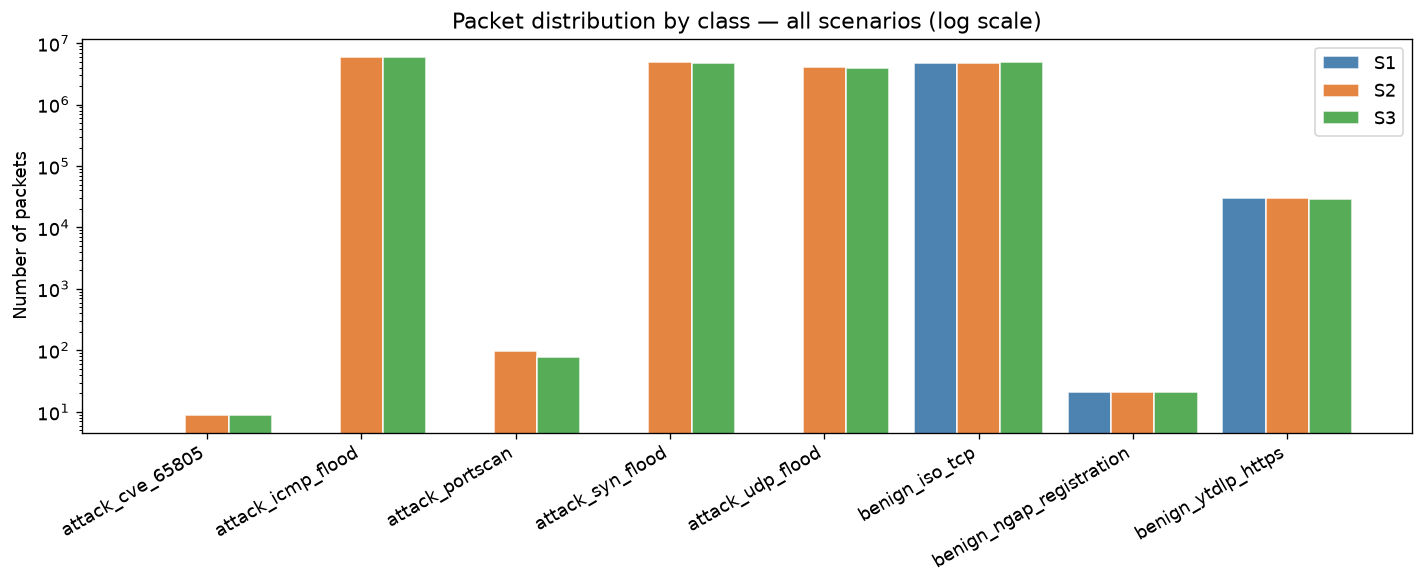

Frames per protocol, analysis PCAP:


,S1,S2,S3
HTTP2,1569,1517,1496
NGAP,18,19,19
SCTP,57,61,57
PFCP,66,66,66
GTP,2908865,2881434,2984571
IP fragments,1936292,1910792,2007651
Other IP,41,14980136,14643396
UDP/2152,2908865,2881495,2984632
ICMP,0,6051989,5920109
Attacker,0,14980101,14643365


In [13]:
if all_counts:
    summary = pd.DataFrame(all_counts).fillna(0).astype(int)
    summary.columns = [f'S{n}' for n in summary.columns]
    display(summary)

    classes = [c for c in summary.index if c not in NON_CLASSES]
    x, w = np.arange(len(classes)), 0.28
    fig, ax = plt.subplots(figsize=(12, 5))
    for i, (col, c) in enumerate(zip(summary.columns, ['#2E6DA4', '#E07020', '#3A9E3A'])):
        ax.bar(x + (i - 1) * w, summary.loc[classes, col], w, label=col, color=c, alpha=0.85,
               edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels(classes, rotation=30, ha='right')
    ax.set_ylabel('Number of packets')
    ax.set_yscale('log')
    ax.set_title('Packet distribution by class — all scenarios (log scale)')
    ax.legend()
    plt.tight_layout()
    fig.savefig(os.path.join(FIGDIR, 'fig_packet_distribution_all.pdf'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

if all_protos:
    print('Frames per protocol, analysis PCAP:')
    display(pd.DataFrame({f'S{n}': p for n, p in all_protos.items()}))

## 7. Flow-level analysis with NFStream

In [14]:
from nfstream import NFStreamer

FLOW_FEATURES = [
    'bidirectional_duration_ms', 'bidirectional_packets', 'bidirectional_bytes',
    'src2dst_packets', 'dst2src_packets', 'src2dst_bytes', 'dst2src_bytes',
    'bidirectional_min_ps', 'bidirectional_mean_ps', 'bidirectional_stddev_ps', 'bidirectional_max_ps',
    'bidirectional_min_piat_ms', 'bidirectional_mean_piat_ms', 'bidirectional_stddev_piat_ms',
    'bidirectional_max_piat_ms', 'bidirectional_syn_packets', 'bidirectional_ack_packets',
    'bidirectional_psh_packets', 'bidirectional_rst_packets', 'bidirectional_fin_packets',
]
if FLOW_ID_FEATURES:
    FLOW_FEATURES += ['protocol', 'dst_port']
print(f'{len(FLOW_FEATURES)} flow features')


def flows_csv(scenario_id):
    return os.path.join(BASE, scenario_id, f'flows_s{sid(scenario_id)}_nfstream.csv')


def extract_flows(scenario_id, force=False):
    bridge, out_csv = pcap_path(scenario_id, 'bridge'), flows_csv(scenario_id)
    if not force and not is_stale(out_csv, bridge):
        print(f'  [cache] {out_csv} is up to date (FORCE_FLOWS=True to regenerate)')
        return out_csv
    print(f'  Running NFStream on {bridge} (may take several minutes)...')
    df = NFStreamer(source=bridge, statistical_analysis=True, idle_timeout=15, active_timeout=60).to_pandas()
    df.to_csv(out_csv, index=False)
    print(f'  Saved {len(df):,} flows -> {out_csv}')
    return out_csv


def _is_any(v):
    return pd.isna(v) or str(v).strip().lower() in ('', 'any', '*')


def label_flows(df, time_labels, flow_labels, ue_set):
    src = df['src_ip'].astype(str).to_numpy().astype('U')
    dst = df['dst_ip'].astype(str).to_numpy().astype('U')
    proto, sport, dport = df['protocol'].to_numpy(), df['src_port'].to_numpy(), df['dst_port'].to_numpy()
    t_first, t_last = df['t_start_s'].to_numpy(), df['t_end_s'].to_numpy()
    sni = (df['requested_server_name'].fillna('').astype(str).str.lower().to_numpy()
           if 'requested_server_name' in df else np.full(len(df), ''))

    lab    = np.full(len(df), None, dtype=object)
    is_att = np.isin(src, list(ATTACKER_IPS)) | np.isin(dst, list(ATTACKER_IPS))

    def port_matters(r):
        tcp_udp = _is_any(r['proto']) or int(float(r['proto'])) in (6, 17)
        return tcp_udp and not _is_any(r['dst_port'])

    rules = flow_labels[flow_labels['label'].str.startswith('attack')].copy()
    rules['_specific'] = rules.apply(port_matters, axis=1).astype(int)
    rules = rules.sort_values('_specific', ascending=False, kind='stable')
    ip_eq = lambda arr, v: np.ones(len(arr), bool) if _is_any(v) else arr == str(v).strip()
    port_eq = lambda arr, r: arr == int(float(r['dst_port'])) if r['_specific'] else np.ones(len(arr), bool)

    report = []
    for _, r in rules.iterrows():
        win = time_labels[time_labels['label'] == r['label']]
        tmask = np.zeros(len(df), bool)
        for _, w in win.iterrows():
            tmask |= (t_first <= w['t_end'] + FLOW_MARGIN_S) & (t_last >= w['t_start'] - FLOW_MARGIN_S)
        if win.empty:
            print(f'  [warn] {r["label"]}: no time window — matched by 5-tuple only')
            tmask[:] = True
        pmask = np.ones(len(df), bool) if _is_any(r['proto']) else proto == int(float(r['proto']))
        fwd = ip_eq(src, r['src_ip']) & ip_eq(dst, r['dst_ip']) & port_eq(dport, r)
        rev = ip_eq(dst, r['src_ip']) & ip_eq(src, r['dst_ip']) & port_eq(sport, r)
        m = pmask & (fwd | rev) & tmask & pd.isna(lab)
        lab[m] = r['label']
        report.append({'label': r['label'], 'proto': r['proto'],
                       'dst_port': r['dst_port'] if r['_specific'] else 'any', 'flows_matched': int(m.sum())})

    lab[pd.isna(lab) & is_att] = 'attacker_other'
    internal = lambda a: np.char.startswith(a, CORE_NET) | is_ue(a, ue_set)
    n6 = ((src == UPF_IP) & ~internal(dst)) | ((dst == UPF_IP) & ~internal(src))
    lab[pd.isna(lab) & n6] = 'n6_duplicate'
    for lbl, pats in BENIGN_SNI.items():
        hit = np.array([any(p in s for p in pats) for s in sni], dtype=bool)
        lab[pd.isna(lab) & hit] = lbl
    for lbl, p in BENIGN_PROTO.items():
        win = np.zeros(len(df), bool)
        for _, w in time_labels[time_labels['label'] == lbl].iterrows():
            win |= (t_first <= w['t_end'] + FLOW_MARGIN_S) & (t_last >= w['t_start'] - FLOW_MARGIN_S)
        lab[pd.isna(lab) & (proto == p) & win] = lbl
    ue = is_ue(src, ue_set) | is_ue(dst, ue_set)
    lab[pd.isna(lab) & ue] = BENIGN_OTHER
    lab[pd.isna(lab)] = 'background'
    return lab, pd.DataFrame(report)


def load_and_label_flows(scenario_id, t0=None):
    n = sid(scenario_id)
    df = pd.read_csv(flows_csv(scenario_id), low_memory=False)
    if t0 is None:
        t0 = df['bidirectional_first_seen_ms'].min() / 1000
        print('  [warn] packet-level T0 not available — first flow is t = 0')
    df['t_start_s'] = df['bidirectional_first_seen_ms'] / 1000 - t0
    df['t_end_s']   = df['bidirectional_last_seen_ms'] / 1000 - t0
    time_labels = load_time_labels(scenario_id, t0)
    flow_labels = pd.read_csv(csv_path(scenario_id, 'labels_flow'))
    df['label'], report = label_flows(df, time_labels, flow_labels, UE.get(n) or ue_ips(scenario_id))
    return df, report


for sc in FLOW_SCENARIOS:
    print(f'=== {sc} ===')
    extract_flows(sc, force=FORCE_FLOWS)

20 flow features
=== scenario_2 ===
  [cache] /home/mac6958/oai-workshops/cn/results/scenario_2/flows_s2_nfstream.csv is up to date (FORCE_FLOWS=True to regenerate)
=== scenario_3 ===
  [cache] /home/mac6958/oai-workshops/cn/results/scenario_3/flows_s3_nfstream.csv is up to date (FORCE_FLOWS=True to regenerate)


  Scenario 2 — flow-level RF


,label,proto,dst_port,flows_matched
0,attack_syn_flood,6,80,65535
1,attack_udp_flood,17,80,65535
2,attack_portscan,6,any,48
3,attack_icmp_flood,1,any,1
4,attack_cve_65805,132,any,1


  attacker_other flows: 1


,src_ip,dst_ip,protocol,src_port,dst_port,bidirectional_packets,t_start_s,t_end_s
74616,192.168.70.132,192.168.70.140,1,0,0,35,141.862937,170.862937



  Flows: 131,761
label
attack_syn_flood            65535
attack_udp_flood            65535
benign_ytdlp_https            280
background                    208
n6_duplicate                  145
attack_portscan                48
benign_other                    4
benign_iso_tcp                  2
benign_ngap_registration        1
attacker_other                  1
attack_cve_65805                1
attack_icmp_flood               1


flows
label              requested_server_name                     
benign_ytdlp_https www.youtube.com                        140
                   manifest.googlevideo.com                70
                   rr1---sn-0n2cg-bg0e.googlevideo.com     70
benign_iso_tcp     releases.ubuntu.com                      2

  [note] Leaving out classes with <10 flow-level, NFStream: benign_iso_tcp (2), benign_ngap_registration (1), attack_cve_65805 (1), attack_icmp_flood (1)



  Classification report (flow-level, NFStream):
                    precision    recall  f1-score   support

   attack_portscan      1.000     1.000     1.000        14
  attack_syn_flood      1.000     1.000     1.000     19661
  attack_udp_flood      1.000     1.000     1.000     19661
benign_ytdlp_https      1.000     1.000     1.000        84

          accuracy                          1.000     39420
         macro avg      1.000     1.000     1.000     39420
      weighted avg      1.000     1.000     1.000     39420



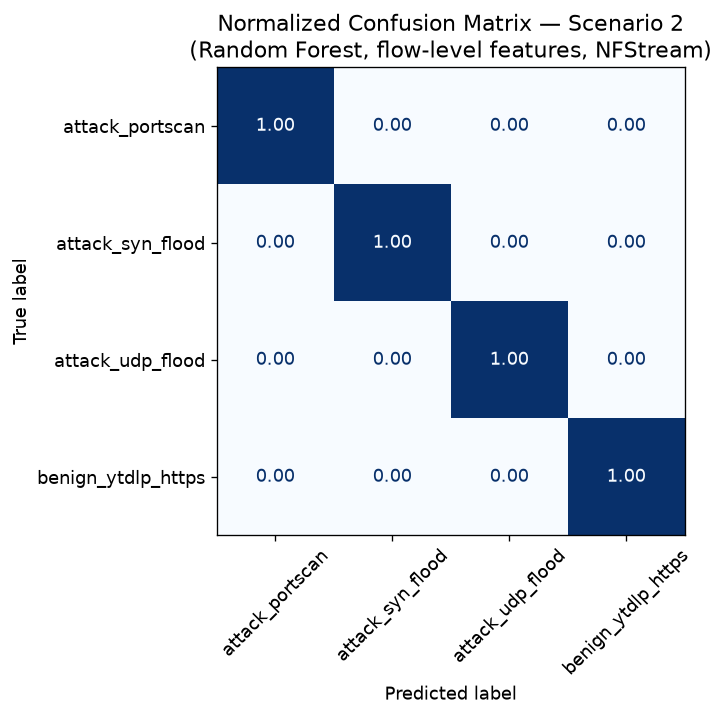

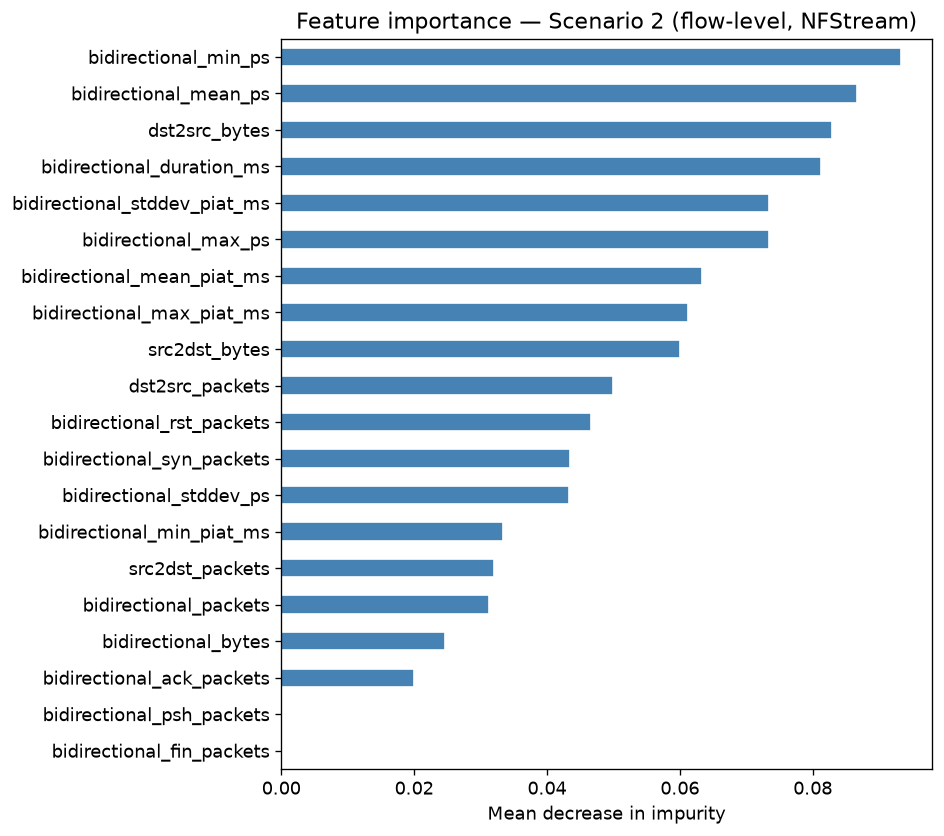

  Scenario 3 — flow-level RF


,label,proto,dst_port,flows_matched
0,attack_syn_flood,6,80,65535
1,attack_udp_flood,17,80,65535
2,attack_portscan,6,any,38
3,attack_icmp_flood,1,any,1
4,attack_cve_65805,132,any,1



  Flows: 131,735
label
attack_syn_flood            65535
attack_udp_flood            65535
benign_ytdlp_https            272
background                    205
n6_duplicate                  141
attack_portscan                38
benign_other                    4
benign_iso_tcp                  2
benign_ngap_registration        1
attack_icmp_flood               1
attack_cve_65805                1


flows
label              requested_server_name                     
benign_ytdlp_https www.youtube.com                        136
                   manifest.googlevideo.com                68
                   rr1---sn-0n2cg-bg0e.googlevideo.com     68
benign_iso_tcp     releases.ubuntu.com                      2

  [note] Leaving out classes with <10 flow-level, NFStream: benign_iso_tcp (2), benign_ngap_registration (1), attack_icmp_flood (1), attack_cve_65805 (1)



  Classification report (flow-level, NFStream):
                    precision    recall  f1-score   support

   attack_portscan      1.000     1.000     1.000        11
  attack_syn_flood      1.000     1.000     1.000     19661
  attack_udp_flood      1.000     1.000     1.000     19660
benign_ytdlp_https      1.000     1.000     1.000        82

          accuracy                          1.000     39414
         macro avg      1.000     1.000     1.000     39414
      weighted avg      1.000     1.000     1.000     39414



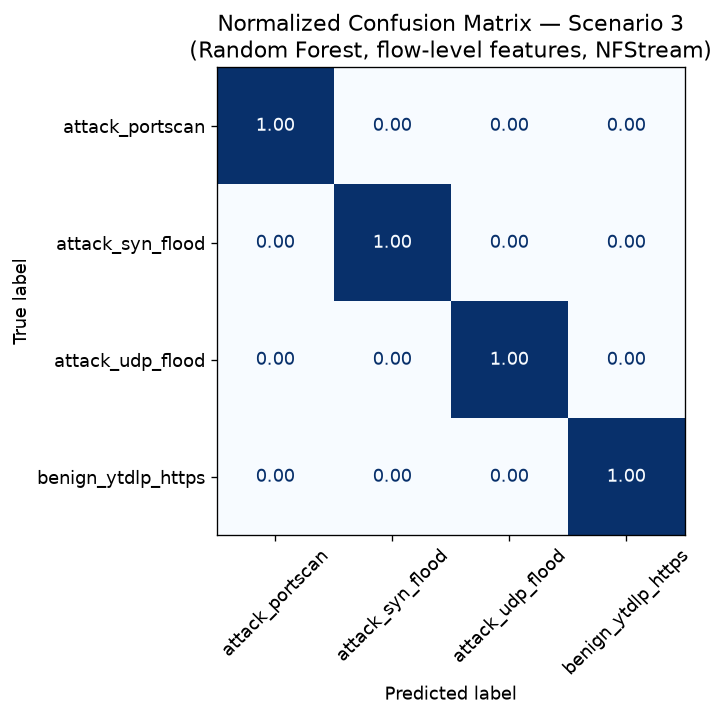

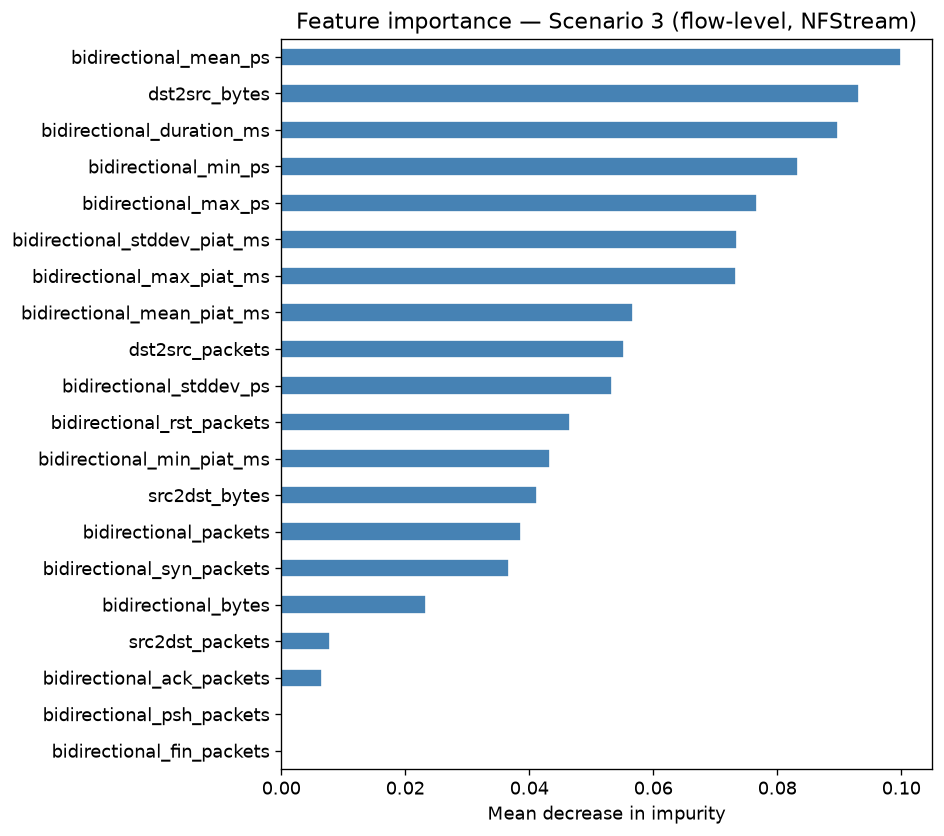

  Flow-level RF — train on Scenario 2, test on Scenario 3
  [note] Leaving out classes with <10 flows: benign_iso_tcp (2), benign_ngap_registration (1), attack_cve_65805 (1), attack_icmp_flood (1)
  [note] Leaving out classes with <10 flows: benign_iso_tcp (2), benign_ngap_registration (1), attack_icmp_flood (1), attack_cve_65805 (1)


                    precision    recall  f1-score   support

   attack_portscan      1.000     1.000     1.000        38
  attack_syn_flood      1.000     1.000     1.000     65535
  attack_udp_flood      1.000     1.000     1.000     65535
benign_ytdlp_https      1.000     1.000     1.000       272

          accuracy                          1.000    131380
         macro avg      1.000     1.000     1.000    131380
      weighted avg      1.000     1.000     1.000    131380



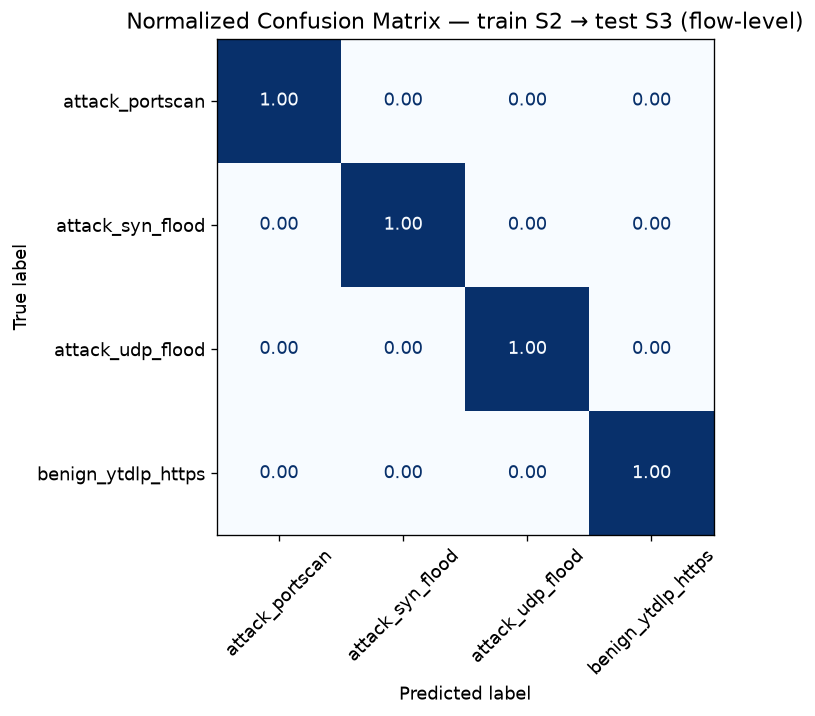

In [15]:
flow_reports, flow_dfs, flow_counts = {}, {}, {}
for sc in FLOW_SCENARIOS:
    n = sid(sc)
    print(f'{"=" * 60}\n  Scenario {n} — flow-level RF\n{"=" * 60}')
    df, rule_report = load_and_label_flows(sc, T0.get(n))
    display(rule_report)
    for lbl, k in rule_report.groupby('label')['flows_matched'].sum().items():
        if k == 0:
            print(f'  [warn] {lbl}: 0 flows matched')
    other = df[df['label'] == 'attacker_other']
    if len(other):
        print(f'  attacker_other flows: {len(other)}')
        display(other[['src_ip', 'dst_ip', 'protocol', 'src_port', 'dst_port',
                       'bidirectional_packets', 't_start_s', 't_end_s']].head(10))
    flow_counts[n] = df['label'].value_counts()
    print(f'\n  Flows: {len(df):,}')
    print(flow_counts[n].to_string())
    if 'requested_server_name' in df:
        top = (df[df['label'].isin(list(BENIGN_SNI))].groupby(['label', 'requested_server_name'])
               .size().rename('flows').sort_values(ascending=False).head(10))
        display(top.to_frame())

    df[FLOW_FEATURES] = df[FLOW_FEATURES].fillna(0)
    flow_dfs[n] = df[FLOW_FEATURES + ['label']]
    rep = run_rf(flow_dfs[n], FLOW_FEATURES, f'Scenario {n}', 'flow-level, NFStream', f'_flow_s{n}',
                 'Random Forest, flow-level features, NFStream')
    if rep is not None:
        flow_reports[n] = rep

if '2' in flow_dfs and '3' in flow_dfs:
    print(f'{"=" * 60}\n  Flow-level RF — train on Scenario 2, test on Scenario 3\n{"=" * 60}')
    cross_flow_report = run_cross(flow_dfs['2'], flow_dfs['3'], FLOW_FEATURES,
                                  'train S2 → test S3 (flow-level)', 'flows', '_flow_cross_s2_s3')

## 8. Packet-level vs flow-level comparison

`—` = class not evaluated at that level (absent, or fewer than `MIN_CLASS_SAMPLES` samples).

In [16]:
AGG = ('accuracy', 'macro avg', 'weighted avg')
for n in ['2', '3']:
    pk, fl = all_reports.get(n, {}), flow_reports.get(n, {})
    if not pk and not fl:
        continue
    rows = []
    for c in sorted({c for rep in (pk, fl) for c in rep if c not in AGG}):
        f1p, f1f = pk.get(c, {}).get('f1-score', np.nan), fl.get(c, {}).get('f1-score', np.nan)
        rows.append({'Class': c, 'F1 (packet)': f1p, 'Support (packet)': pk.get(c, {}).get('support', np.nan),
                     'F1 (flow)': f1f, 'Support (flow)': fl.get(c, {}).get('support', np.nan),
                     'Delta': f1f - f1p})
    print(f'Scenario {n}:')
    display(pd.DataFrame(rows).set_index('Class').style
            .format({'F1 (packet)': '{:.3f}', 'F1 (flow)': '{:.3f}', 'Delta': '{:+.3f}',
                     'Support (packet)': '{:,.0f}', 'Support (flow)': '{:,.0f}'}, na_rep='—'))

Scenario 2:


,F1 (packet),Support (packet),F1 (flow),Support (flow),Delta
Class,,,,,
attack_icmp_flood,1.000,"1,815,587",—,—,—
attack_portscan,0.800,29,1.000,14,+0.200
attack_syn_flood,1.000,"1,461,457",1.000,"19,661",+0.000
attack_udp_flood,1.000,"1,216,945",1.000,"19,661",+0.000
benign_ngap_registration,1.000,6,—,—,—
benign_user_plane,1.000,"864,428",—,—,—
benign_ytdlp_https,—,—,1.000,84,—


Scenario 3:


,F1 (packet),Support (packet),F1 (flow),Support (flow),Delta
Class,,,,,
attack_icmp_flood,1.000,"1,776,022",—,—,—
attack_portscan,0.759,23,1.000,11,+0.241
attack_syn_flood,1.000,"1,418,763",1.000,"19,661",+0.000
attack_udp_flood,1.000,"1,198,188",1.000,"19,660",+0.000
benign_ngap_registration,1.000,7,—,—,—
benign_user_plane,1.000,"895,369",—,—,—
benign_ytdlp_https,—,—,1.000,82,—
